# Clickstream to Conversion
## Exploratory Data Analysis, Statistical Distribution Analysis and MLP-Based Prediction of Online Shoppers' Purchasing Intention

**Student:** Nakul T (24AD068), III Year B.Tech. Artificial Intelligence and Data Science
**Course:** U21ADP05 Exploratory Data Analysis and Visualization (Assignment II, Case Study)
**Institution:** KPR Institute of Engineering and Technology, Coimbatore

**Dataset:** Online Shoppers Purchasing Intention Dataset, UCI Machine Learning Repository (id 468),
12,330 browsing sessions x 18 fields (10 numerical, 7 categorical, 1 binary target `Revenue`).

The notebook is organised around Ben Fry's seven stages of visualization:

| Stage | Where it happens in this notebook |
|---|---|
| Acquire | Section 1: load the CSV obtained from the UCI repository |
| Parse | Section 1: data types, data dictionary, variable roles |
| Filter | Section 2: missing values, logical checks, duplicates, outliers |
| Mine | Sections 3 to 5 and 8: statistics, distribution fitting, hypothesis tests, PCA, deep learning |
| Represent | Every figure: choice of chart type for each question |
| Refine | Colour-blind-safe palette, log scales, annotations, consistent labels |
| Interact | Section 6: self-contained HTML dashboard (`dashboard/index.html`) |

In [1]:
# ============================================================================
# 0. SETUP: imports, paths, reproducibility and a common plot style
# ============================================================================
import os
import sys
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # headless backend when run as a plain script
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, to_rgba
from matplotlib.patches import FancyBboxPatch
from cycler import cycler
from scipy import stats, optimize

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (roc_auc_score, average_precision_score, roc_curve,
                             precision_recall_curve, confusion_matrix, accuracy_score,
                             balanced_accuracy_score, precision_score, recall_score,
                             f1_score, matthews_corrcoef)

warnings.filterwarnings("ignore")
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")

SEED = 42
FAST = os.environ.get("FAST_RUN", "0") == "1"   # quick smoke-test mode (fewer tuning runs)
np.random.seed(SEED)

# Resolve the project root whether the code runs from /notebooks, /src or the repo root
HERE = Path.cwd()
ROOT = HERE.parent if HERE.name in {"notebooks", "src"} else HERE
DATA_PATH = ROOT / "data" / "online_shoppers_intention.csv"
FIG_DIR, RES_DIR, DASH_DIR = ROOT / "figures", ROOT / "results", ROOT / "dashboard"
for d in (FIG_DIR, RES_DIR, DASH_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Colour-blind-safe categorical palette (validated: adjacent CVD delta-E >= 9.1), fixed order
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, AXIS = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
NEUTRAL = "#d6d5ce"                    # observed data shown behind fitted models
BUY, NOBUY = BLUE, ORANGE              # purchase sessions are always blue, non-purchase orange
SEQ = LinearSegmentedColormap.from_list("blue_seq", ["#f6f9fe", "#cde2fb", "#9ec5f4", "#6da7ec",
                                                      "#3987e5", "#256abf", "#184f95", "#0d366b"])
DIV = LinearSegmentedColormap.from_list("blue_red", ["#0d366b", "#256abf", "#86b6ef", "#f0efec",
                                                      "#f19c9b", "#e34948", "#9b2524"])
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "Arial", "DejaVu Sans"],
    "font.size": 9.5, "axes.titlesize": 10.5, "axes.labelsize": 9.5, "axes.titlecolor": INK,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5, "legend.fontsize": 8.5, "legend.frameon": False,
    "text.color": INK, "axes.labelcolor": INK2, "xtick.color": AXIS, "ytick.color": AXIS,
    "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.grid": True, "axes.grid.axis": "y", "grid.color": GRID, "grid.linewidth": 0.7,
    "grid.linestyle": "-", "axes.axisbelow": True, "lines.linewidth": 1.8, "lines.solid_capstyle": "round",
    "figure.dpi": 110, "savefig.dpi": 220, "image.cmap": "Blues",
    "axes.prop_cycle": cycler(color=[BLUE, ORANGE, AQUA, YELLOW]),
})

RESULTS = {}                          # every number quoted in the report is stored here


def save(fig, name):
    """Save a figure as a high-resolution PNG and show it inline in the notebook."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)


def r(x, k=4):
    """Round numpy scalars so that they serialise cleanly to JSON."""
    return float(round(float(x), k))


def wash(color, alpha=0.18):
    """Light fill of a series colour (used inside box plots and bands)."""
    return to_rgba(color, alpha)

## 1. Acquire and Parse

In [2]:
raw = pd.read_csv(DATA_PATH)
print("Shape:", raw.shape)

NUM = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
       "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
       "PageValues", "SpecialDay"]
CAT = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType", "Weekend"]
TARGET = "Revenue"
MONTHS = ["Feb", "Mar", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

# Data dictionary (role, type and meaning of each field)
DESCR = {
    "Administrative": "Number of account/administrative pages visited",
    "Administrative_Duration": "Total time on administrative pages (s)",
    "Informational": "Number of informational pages visited",
    "Informational_Duration": "Total time on informational pages (s)",
    "ProductRelated": "Number of product-related pages visited",
    "ProductRelated_Duration": "Total time on product-related pages (s)",
    "BounceRates": "Mean bounce rate of the pages visited",
    "ExitRates": "Mean exit rate of the pages visited",
    "PageValues": "Mean page value of pages visited before a transaction",
    "SpecialDay": "Closeness of the visit to a special day (0 to 1)",
    "Month": "Month of the visit",
    "OperatingSystems": "Operating system (integer code)",
    "Browser": "Browser (integer code)",
    "Region": "Geographic region (integer code)",
    "TrafficType": "Traffic source (integer code)",
    "VisitorType": "New, Returning or Other visitor",
    "Weekend": "Whether the visit fell on a weekend",
    "Revenue": "Target: whether the session ended in a purchase",
}
dictionary = pd.DataFrame({
    "Field": raw.columns,
    "Pandas dtype": [str(raw[c].dtype) for c in raw.columns],
    "Role": ["Numerical" if c in NUM else "Target" if c == TARGET else "Categorical" for c in raw.columns],
    "Unique values": [raw[c].nunique() for c in raw.columns],
    "Description": [DESCR[c] for c in raw.columns],
})
dictionary.to_csv(RES_DIR / "data_dictionary.csv", index=False)
dictionary

Shape: (12330, 18)


,Field,Pandas dtype,Role,Unique values,Description
0,Administrative,int64,Numerical,27,Number of account/administrative pages visited
1,Administrative_Duration,float64,Numerical,3335,Total time on administrative pages (s)
2,Informational,int64,Numerical,17,Number of informational pages visited
3,Informational_Duration,float64,Numerical,1258,Total time on informational pages (s)
4,ProductRelated,int64,Numerical,311,Number of product-related pages visited
5,ProductRelated_Duration,float64,Numerical,9551,Total time on product-related pages (s)
6,BounceRates,float64,Numerical,1872,Mean bounce rate of the pages visited
7,ExitRates,float64,Numerical,4777,Mean exit rate of the pages visited
8,PageValues,float64,Numerical,2704,Mean page value of pages visited before a tran...
9,SpecialDay,float64,Numerical,6,Closeness of the visit to a special day (0 to 1)


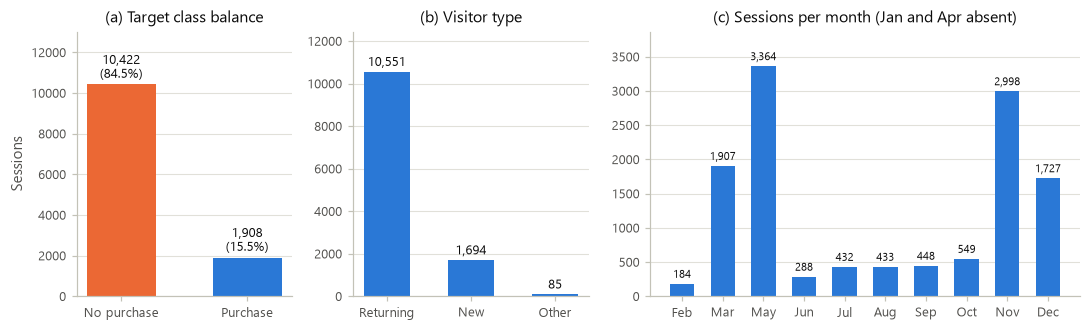

In [3]:
# Figure: composition of the dataset (target balance, visitor type, sessions by month)
fig, ax = plt.subplots(1, 3, figsize=(10, 3.1), gridspec_kw={"width_ratios": [1, 1.1, 2]})
vc = raw[TARGET].value_counts().reindex([False, True])
ax[0].bar(["No purchase", "Purchase"], vc.values, color=[NOBUY, BUY], width=0.55)
for i, v in enumerate(vc.values):
    ax[0].text(i, v + 150, f"{v:,}\n({100 * v / len(raw):.1f}%)", ha="center", va="bottom", fontsize=8.5)
ax[0].set_ylim(0, vc.max() * 1.25); ax[0].set_title("(a) Target class balance"); ax[0].set_ylabel("Sessions")
vt = raw["VisitorType"].value_counts()
ax[1].bar([s.replace("_Visitor", "") for s in vt.index], vt.values, color=BLUE, width=0.55)
for i, v in enumerate(vt.values):
    ax[1].text(i, v + 150, f"{v:,}", ha="center", va="bottom", fontsize=8.5)
ax[1].set_ylim(0, vt.max() * 1.18); ax[1].set_title("(b) Visitor type")
mc = raw["Month"].value_counts().reindex(MONTHS)
ax[2].bar([m[:3] for m in MONTHS], mc.values, color=BLUE, width=0.6)
for i, v in enumerate(mc.values):
    ax[2].text(i, v + 50, f"{v:,}", ha="center", va="bottom", fontsize=7.5)
ax[2].set_ylim(0, mc.max() * 1.15); ax[2].set_title("(c) Sessions per month (Jan and Apr absent)")
fig.tight_layout()
save(fig, "f01_dataset_composition")

RESULTS["dataset"] = {
    "rows": int(raw.shape[0]), "cols": int(raw.shape[1]),
    "purchase_n": int(vc[True]), "purchase_pct": r(100 * vc[True] / len(raw), 2),
    "visitor_counts": {k: int(v) for k, v in vt.items()},
    "month_counts": {k: int(v) for k, v in mc.items()},
}

## 2. Filter: data-quality audit (missing values, logical checks, duplicates, outliers)

In [4]:
audit = {"explicit_missing": int(raw.isna().sum().sum())}

# Implicit problems: a page count and its duration should agree with each other
logic_rows = []
for cnt, dur in [("Administrative", "Administrative_Duration"),
                 ("Informational", "Informational_Duration"),
                 ("ProductRelated", "ProductRelated_Duration")]:
    logic_rows.append({
        "Pair": f"{cnt} / {dur}",
        "count = 0 but duration > 0": int(((raw[cnt] == 0) & (raw[dur] > 0)).sum()),
        "count > 0 but duration = 0": int(((raw[cnt] > 0) & (raw[dur] == 0)).sum()),
    })
logic = pd.DataFrame(logic_rows)
audit["logic"] = logic.to_dict(orient="records")
audit["rates_within_0_0.2"] = bool(raw["BounceRates"].between(0, 0.2).all() and raw["ExitRates"].between(0, 0.2).all())
audit["negative_values"] = int((raw[NUM] < 0).sum().sum())

# Exact duplicate rows
dup_mask = raw.duplicated(keep="first")
dups = raw[dup_mask]
audit["duplicates"] = int(dup_mask.sum())
audit["dup_single_product_page_pct"] = r(100 * (dups["ProductRelated"] <= 1).mean(), 1)
audit["dup_bounce_0.2_pct"] = r(100 * (dups["BounceRates"] == 0.2).mean(), 1)
audit["dup_zero_duration_pct"] = r(100 * (dups["ProductRelated_Duration"] == 0).mean(), 1)
audit["dup_revenue_pct"] = r(100 * dups[TARGET].mean(), 1)

df = raw.drop_duplicates().reset_index(drop=True)
audit["rows_after_dedup"] = int(len(df))
audit["purchase_pct_after_dedup"] = r(100 * df[TARGET].mean(), 2)
print(json.dumps(audit, indent=1))
logic

{
 "explicit_missing": 0,
 "logic": [
  {
   "Pair": "Administrative / Administrative_Duration",
   "count = 0 but duration > 0": 0,
   "count > 0 but duration = 0": 135
  },
  {
   "Pair": "Informational / Informational_Duration",
   "count = 0 but duration > 0": 0,
   "count > 0 but duration = 0": 226
  },
  {
   "Pair": "ProductRelated / ProductRelated_Duration",
   "count = 0 but duration > 0": 0,
   "count > 0 but duration = 0": 717
  }
 ],
 "rates_within_0_0.2": true,
 "negative_values": 0,
 "duplicates": 125,
 "dup_single_product_page_pct": 94.4,
 "dup_bounce_0.2_pct": 100.0,
 "dup_zero_duration_pct": 100.0,
 "dup_revenue_pct": 0.0,
 "rows_after_dedup": 12205,
 "purchase_pct_after_dedup": 15.63
}


,Pair,count = 0 but duration > 0,count > 0 but duration = 0
0,Administrative / Administrative_Duration,0,135
1,Informational / Informational_Duration,0,226
2,ProductRelated / ProductRelated_Duration,0,717


In [5]:
# Outlier screening: Tukey's IQR fences versus |z| > 3 before and after a log1p transform
out_rows = []
for c in NUM:
    s = df[c]
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    hi = q3 + 1.5 * iqr
    n_iqr = int(((s < q1 - 1.5 * iqr) | (s > hi)).sum())
    z_raw = (s - s.mean()) / s.std()
    ls = np.log1p(s)
    z_log = (ls - ls.mean()) / ls.std()
    out_rows.append({"Feature": c, "Q1": r(q1, 3), "Q3": r(q3, 3), "Upper fence": r(hi, 3),
                     "IQR outliers": n_iqr, "IQR outliers (%)": r(100 * n_iqr / len(s), 1),
                     "|z|>3 raw": int((z_raw.abs() > 3).sum()), "|z|>3 after log1p": int((z_log.abs() > 3).sum())})
outliers = pd.DataFrame(out_rows)
outliers.to_csv(RES_DIR / "outlier_screen.csv", index=False)
RESULTS["outliers"] = outliers.to_dict(orient="records")
outliers

,Feature,Q1,Q3,Upper fence,IQR outliers,IQR outliers (%),|z|>3 raw,|z|>3 after log1p
0,Administrative,0.000,4.000,10.000,404,3.3,213,0
1,Administrative_Duration,0.000,94.700,236.750,1149,9.4,230,0
2,Informational,0.000,0.000,0.000,2631,21.6,260,260
3,Informational_Duration,0.000,0.000,0.000,2405,19.7,229,177
4,ProductRelated,8.000,38.000,83.000,1007,8.3,236,6
5,ProductRelated_Duration,193.000,1477.155,3403.387,951,7.8,217,630
6,BounceRates,0.000,0.017,0.042,1428,11.7,593,596
7,ExitRates,0.014,0.049,0.100,1325,10.9,599,595
8,PageValues,0.000,0.000,0.000,2730,22.4,257,125
9,SpecialDay,0.000,0.000,0.000,1249,10.2,478,478


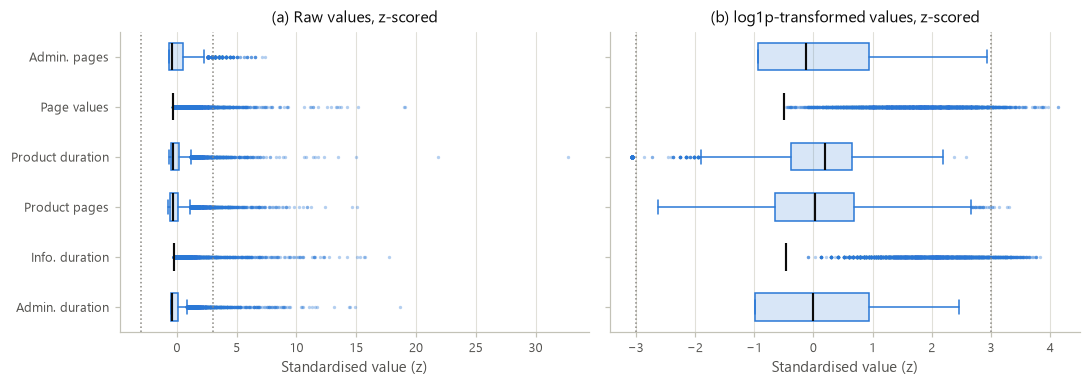

In [6]:
# Figure: standardised box plots of heavy-tailed features, raw scale versus log1p scale
heavy = ["Administrative_Duration", "Informational_Duration", "ProductRelated",
         "ProductRelated_Duration", "PageValues", "Administrative"]
short = {"Administrative_Duration": "Admin. duration", "Informational_Duration": "Info. duration",
         "ProductRelated": "Product pages", "ProductRelated_Duration": "Product duration",
         "PageValues": "Page values", "Administrative": "Admin. pages"}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.6), sharey=True)
for k, (title, tf) in enumerate([("(a) Raw values, z-scored", lambda s: s),
                                  ("(b) log1p-transformed values, z-scored", np.log1p)]):
    data = []
    for c in heavy:
        v = tf(df[c].astype(float))
        data.append(((v - v.mean()) / v.std()).values)
    bp = ax[k].boxplot(data, vert=False, widths=0.55, patch_artist=True,
                       flierprops=dict(marker="o", markersize=2.2, markerfacecolor=BLUE, markeredgecolor="none", alpha=0.35),
                       medianprops=dict(color=INK, linewidth=1.4),
                       whiskerprops=dict(color=BLUE), capprops=dict(color=BLUE))
    for b in bp["boxes"]:
        b.set(facecolor=wash(BLUE), edgecolor=BLUE)
    for xv in (-3, 3):
        ax[k].axvline(xv, ls=":", color=MUTED, lw=1)
    ax[k].set_title(title); ax[k].set_xlabel("Standardised value (z)")
    ax[k].grid(axis="x"); ax[k].grid(axis="y", visible=False)
ax[0].set_yticks(range(1, len(heavy) + 1), [short[c] for c in heavy])
fig.tight_layout()
save(fig, "f02_outlier_boxplots")

## 3. Mine (I): univariate analysis, transformations and inequality

In [7]:
q = df[NUM].quantile([0, 0.25, 0.5, 0.75, 1]).T
q.columns = ["Min", "Q1", "Median", "Q3", "Max"]
moments = pd.DataFrame({
    "Mean": df[NUM].mean(), "SD": df[NUM].std(),
    "MAD": df[NUM].apply(lambda s: stats.median_abs_deviation(s)),
    "Skewness": df[NUM].skew(), "Excess kurtosis": df[NUM].kurt(),
    "Zeros (%)": (df[NUM] == 0).mean() * 100,
})
univariate = pd.concat([q, moments], axis=1).round(3)
univariate.to_csv(RES_DIR / "univariate_summary.csv")
RESULTS["univariate"] = {c: {k: r(v, 3) for k, v in univariate.loc[c].items()} for c in NUM}
univariate

,Min,Q1,Median,Q3,Max,Mean,SD,MAD,Skewness,Excess kurtosis,Zeros (%)
Administrative,0.0,0.000,1.000,4.000,27.000,2.339,3.330,1.000,1.947,4.641,46.235
Administrative_Duration,0.0,0.000,9.000,94.700,3398.750,81.646,177.492,9.000,5.592,50.137,47.341
Informational,0.0,0.000,0.000,0.000,24.000,0.509,1.276,0.000,4.014,26.659,78.443
Informational_Duration,0.0,0.000,0.000,0.000,2549.375,34.825,141.425,0.000,7.540,75.534,80.295
ProductRelated,0.0,8.000,18.000,38.000,705.000,32.046,44.594,13.000,4.333,31.073,0.311
ProductRelated_Duration,0.0,193.000,608.943,1477.155,63973.522,1206.982,1919.601,502.443,7.253,136.681,5.162
BounceRates,0.0,0.000,0.003,0.017,0.200,0.020,0.045,0.003,3.162,9.334,45.211
ExitRates,0.0,0.014,0.025,0.049,0.200,0.041,0.046,0.014,2.235,4.642,0.623
PageValues,0.0,0.000,0.000,0.000,361.764,5.950,18.654,0.000,6.351,64.998,77.632
SpecialDay,0.0,0.000,0.000,0.000,1.000,0.062,0.200,0.000,3.286,9.798,89.766


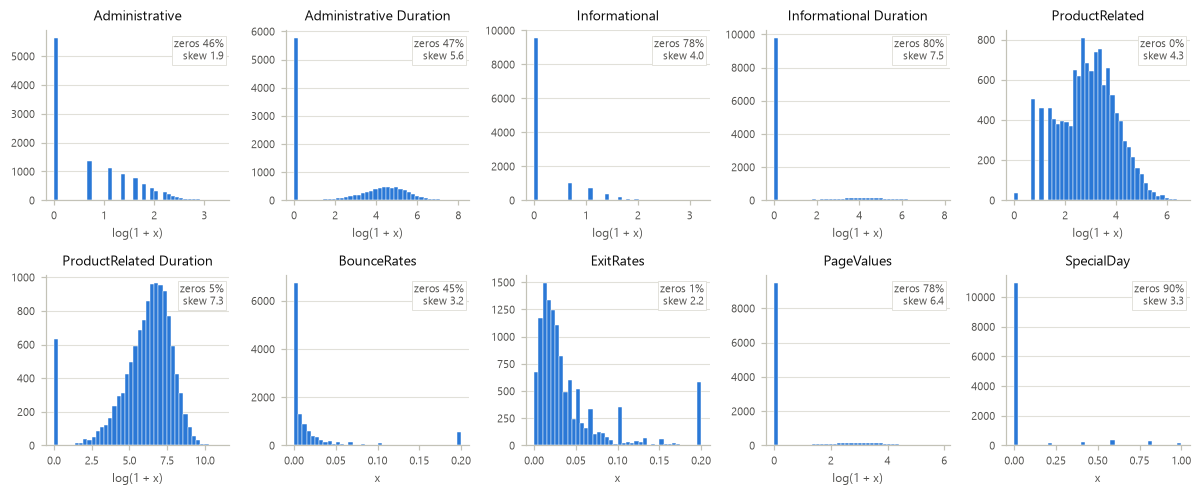

In [8]:
# Figure: small-multiple histograms for all ten numerical features
fig, axes = plt.subplots(2, 5, figsize=(11, 4.6))
for ax_, c in zip(axes.ravel(), NUM):
    s = df[c].astype(float)
    logged = c not in ("BounceRates", "ExitRates", "SpecialDay")
    v = np.log1p(s) if logged else s
    ax_.hist(v, bins=40, color=BLUE, edgecolor="white", linewidth=0.3)
    ax_.set_title(c.replace("_", " "), fontsize=9)
    ax_.set_xlabel("log(1 + x)" if logged else "x", fontsize=8)
    ax_.text(0.97, 0.95, f"zeros {100 * (s == 0).mean():.0f}%\nskew {s.skew():.1f}",
             transform=ax_.transAxes, ha="right", va="top", fontsize=7.5, color=INK2,
             bbox=dict(facecolor="white", edgecolor=GRID, linewidth=0.6, pad=1.5))
    ax_.tick_params(labelsize=7.5)
fig.tight_layout()
save(fig, "f04_univariate_panel")

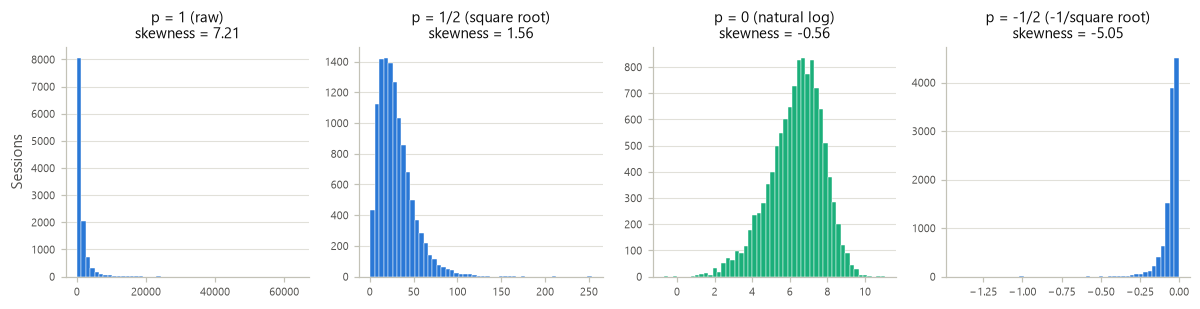

{'p = 1 (raw)': 7.209,
 'p = 1/2 (square root)': 1.557,
 'p = 0 (natural log)': -0.558,
 'p = -1/2 (-1/square root)': -5.046}

In [9]:
# Tukey's ladder of powers applied to positive product-browsing durations
pos = df.loc[df["ProductRelated_Duration"] > 0, "ProductRelated_Duration"].astype(float)
ladder = [("p = 1 (raw)", pos), ("p = 1/2 (square root)", np.sqrt(pos)),
          ("p = 0 (natural log)", np.log(pos)), ("p = -1/2 (-1/square root)", -1 / np.sqrt(pos))]
fig, ax = plt.subplots(1, 4, figsize=(11, 2.9))
ladder_skew = {}
for a, (name, v) in zip(ax, ladder):
    sk = stats.skew(v)
    ladder_skew[name] = r(sk, 3)
    a.hist(v, bins=50, color=AQUA if "log" in name else BLUE, edgecolor="white", linewidth=0.3)
    a.set_title(f"{name}\nskewness = {sk:.2f}", fontsize=9.5)
    a.tick_params(labelsize=7.5)
ax[0].set_ylabel("Sessions")
fig.tight_layout()
save(fig, "f03_ladder_of_powers")
RESULTS["ladder_skew"] = ladder_skew
RESULTS["ladder_n_positive"] = int(len(pos))
ladder_skew

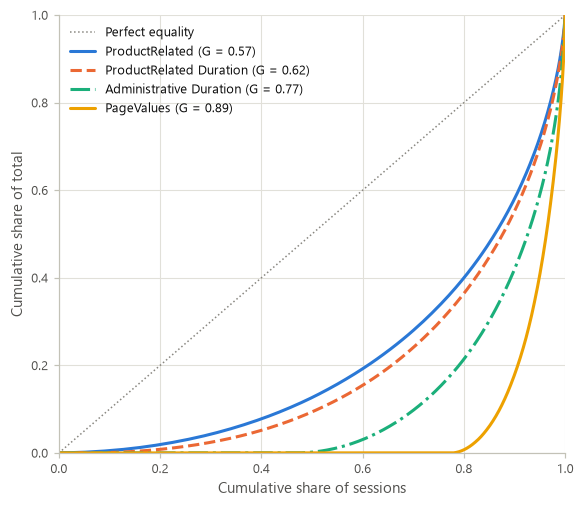

{'ProductRelated': {'gini': 0.569, 'top10_share_pct': 42.0},
 'ProductRelated_Duration': {'gini': 0.618, 'top10_share_pct': 44.8},
 'Administrative_Duration': {'gini': 0.77, 'top10_share_pct': 58.0},
 'PageValues': {'gini': 0.895, 'top10_share_pct': 82.1}}

In [10]:
def lorenz_curve(x):
    """Return the Lorenz curve (population share, value share) and the Gini coefficient."""
    x = np.sort(np.asarray(x, dtype=float))
    cum = np.insert(np.cumsum(x) / x.sum(), 0, 0.0)
    pop = np.linspace(0, 1, len(cum))
    gini = 1 - 2 * np.trapezoid(cum, pop)
    return pop, cum, gini


fig, ax = plt.subplots(figsize=(5.4, 4.7))
ax.plot([0, 1], [0, 1], color=MUTED, lw=1, ls=":", label="Perfect equality")
lor = {}
for c, col, ls_ in [("ProductRelated", BLUE, "-"), ("ProductRelated_Duration", ORANGE, "--"),
                    ("Administrative_Duration", AQUA, "-."), ("PageValues", YELLOW, "-")]:
    pop, cum, g = lorenz_curve(df[c])
    top10 = 1 - np.interp(0.9, pop, cum)
    lor[c] = {"gini": r(g, 3), "top10_share_pct": r(100 * top10, 1)}
    ax.plot(pop, cum, color=col, ls=ls_, lw=2, label=f"{c.replace('_', ' ')} (G = {g:.2f})")
ax.set_xlabel("Cumulative share of sessions")
ax.set_ylabel("Cumulative share of total")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
ax.grid(axis="x")
ax.legend(loc="upper left", fontsize=8.2)
fig.tight_layout()
save(fig, "f05_lorenz_gini")
RESULTS["lorenz"] = lor
lor

## 4. Mine (II): probability distributions (discrete and continuous)

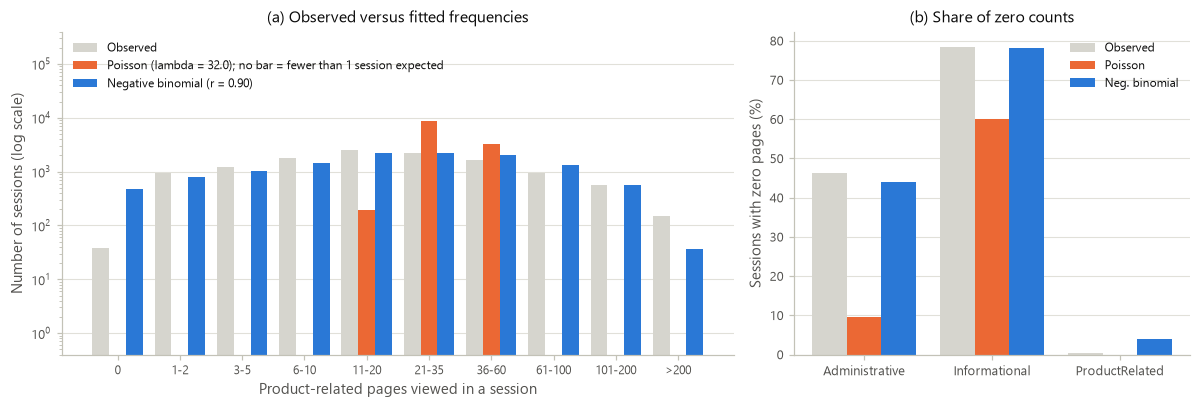

,Feature,Mean,Variance,Dispersion index,Observed zeros (%),Poisson zeros (%),NegBin zeros (%)
0,Administrative,2.339,11.091,4.74,46.24,9.64,43.97
1,Informational,0.509,1.627,3.20,78.44,60.13,78.15
2,ProductRelated,32.046,1988.431,62.05,0.31,0.00,3.93


In [11]:
def fit_negbin(x):
    """Maximum-likelihood negative binomial fit (scipy parameterisation n=r, p)."""
    x = np.asarray(x)
    m, v = x.mean(), x.var()
    r0 = m ** 2 / max(v - m, 1e-6)
    p0 = r0 / (r0 + m)

    def nll(theta):
        rr, pp = np.exp(theta[0]), 1 / (1 + np.exp(-theta[1]))
        return -stats.nbinom.logpmf(x, rr, pp).sum()

    res = optimize.minimize(nll, [np.log(r0), np.log(p0 / (1 - p0))], method="Nelder-Mead",
                            options={"xatol": 1e-8, "fatol": 1e-8, "maxiter": 4000})
    return np.exp(res.x[0]), 1 / (1 + np.exp(-res.x[1])), -res.fun


x_pr = df["ProductRelated"].to_numpy()
lam = x_pr.mean()
r_nb, p_nb, ll_nb = fit_negbin(x_pr)
ll_po = stats.poisson.logpmf(x_pr, lam).sum()
edges = [0, 1, 3, 6, 11, 21, 36, 61, 101, 201, np.inf]
labels = ["0", "1-2", "3-5", "6-10", "11-20", "21-35", "36-60", "61-100", "101-200", ">200"]
obs = np.array([((x_pr >= lo) & (x_pr < hi)).sum() for lo, hi in zip(edges[:-1], edges[1:])])


def binned_expected(cdf):
    out = []
    for lo, hi in zip(edges[:-1], edges[1:]):
        upper = 1.0 if np.isinf(hi) else cdf(hi - 1)
        lower = 0.0 if lo == 0 else cdf(lo - 1)
        out.append(len(x_pr) * (upper - lower))
    return np.array(out)


exp_po = binned_expected(lambda k: stats.poisson.cdf(k, lam))
exp_nb = binned_expected(lambda k: stats.nbinom.cdf(k, r_nb, p_nb))
chi_nb = ((obs - exp_nb) ** 2 / exp_nb).sum()
chi_po = ((obs - exp_po) ** 2 / np.maximum(exp_po, 1e-9)).sum()
p_chi_nb = stats.chi2.sf(chi_nb, len(obs) - 1 - 2)

zero_rows = []
for c in ["Administrative", "Informational", "ProductRelated"]:
    xc = df[c].to_numpy()
    rr, pp, _ = fit_negbin(xc)
    zero_rows.append({"Feature": c, "Mean": r(xc.mean(), 3), "Variance": r(xc.var(), 3),
                      "Dispersion index": r(xc.var() / xc.mean(), 2),
                      "Observed zeros (%)": r(100 * (xc == 0).mean(), 2),
                      "Poisson zeros (%)": r(100 * np.exp(-xc.mean()), 2),
                      "NegBin zeros (%)": r(100 * stats.nbinom.pmf(0, rr, pp), 2)})
zeros = pd.DataFrame(zero_rows)

RESULTS["discrete_fit"] = {
    "lambda": r(lam, 3), "variance": r(x_pr.var(), 2), "dispersion_index": r(x_pr.var() / lam, 2),
    "nb_r": r(r_nb, 4), "nb_p": r(p_nb, 5), "ll_poisson": r(ll_po, 1), "ll_negbin": r(ll_nb, 1),
    "aic_poisson": r(2 - 2 * ll_po, 1), "aic_negbin": r(4 - 2 * ll_nb, 1),
    "chi2_poisson": r(chi_po, 1), "chi2_negbin": r(chi_nb, 1), "p_chi2_negbin": float(p_chi_nb),
    "bins": labels, "observed": obs.tolist(), "expected_poisson": [r(v, 1) for v in exp_po],
    "expected_negbin": [r(v, 1) for v in exp_nb], "zeros_table": zeros.to_dict(orient="records"),
}

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), gridspec_kw={"width_ratios": [1.7, 1]})
xpos = np.arange(len(labels))
w = 0.27
ax[0].bar(xpos - w, obs, w, color=NEUTRAL, label="Observed")
ax[0].bar(xpos, np.where(exp_po >= 0.5, exp_po, np.nan), w, color=ORANGE,
          label=f"Poisson (lambda = {lam:.1f}); no bar = fewer than 1 session expected")
ax[0].bar(xpos + w, exp_nb, w, color=BLUE, label=f"Negative binomial (r = {r_nb:.2f})")
ax[0].set_yscale("log"); ax[0].set_ylim(0.4, 4e5)
ax[0].set_xticks(xpos, labels, rotation=0, fontsize=8)
ax[0].set_xlabel("Product-related pages viewed in a session")
ax[0].set_ylabel("Number of sessions (log scale)")
ax[0].set_title("(a) Observed versus fitted frequencies")
ax[0].legend(loc="upper left", fontsize=8)
zx = np.arange(len(zeros))
ax[1].bar(zx - w, zeros["Observed zeros (%)"], w, color=NEUTRAL, label="Observed")
ax[1].bar(zx, zeros["Poisson zeros (%)"], w, color=ORANGE, label="Poisson")
ax[1].bar(zx + w, zeros["NegBin zeros (%)"], w, color=BLUE, label="Neg. binomial")
ax[1].set_xticks(zx, ["Administrative", "Informational", "ProductRelated"], fontsize=8.5)
ax[1].set_ylabel("Sessions with zero pages (%)")
ax[1].set_title("(b) Share of zero counts")
ax[1].legend(fontsize=8)
fig.tight_layout()
save(fig, "f06_discrete_fit")
zeros

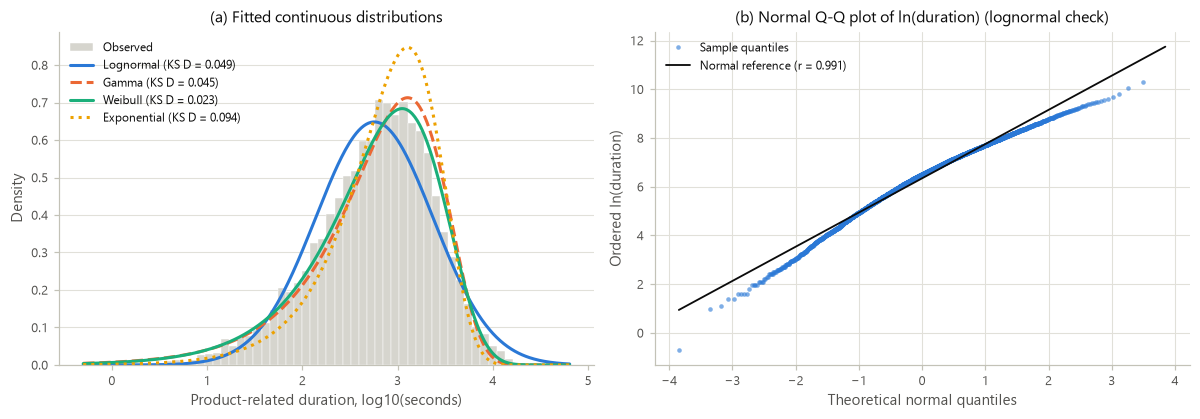

,AIC,KS D
Weibull,187568.6,0.0233
Lognormal,187817.2,0.0487
Gamma,187913.5,0.0455
Exponential,188648.5,0.0942


In [12]:
# Continuous distributions for positive product-browsing time
y_dur = pos.to_numpy()
cands = {"Lognormal": stats.lognorm, "Gamma": stats.gamma, "Weibull": stats.weibull_min, "Exponential": stats.expon}
cont = {}
for name, dist in cands.items():
    params = dist.fit(y_dur, floc=0)
    ll = dist.logpdf(y_dur, *params).sum()
    k = len(params) - 1
    ks = stats.kstest(y_dur, dist.cdf, args=params)
    cont[name] = {"params": [float(p) for p in params], "loglik": r(ll, 1), "aic": r(2 * k - 2 * ll, 1),
                  "ks_D": r(ks.statistic, 4), "ks_p": float(ks.pvalue)}
cont_table = pd.DataFrame({k: {"AIC": v["aic"], "KS D": v["ks_D"]} for k, v in cont.items()}).T.sort_values("AIC")
ln_mu, ln_sigma = np.log(y_dur).mean(), np.log(y_dur).std(ddof=1)
RESULTS["continuous_fit"] = cont
RESULTS["continuous_fit_rank"] = list(cont_table.index)
RESULTS["lognormal_mu_sigma"] = [r(ln_mu, 3), r(ln_sigma, 3)]
RESULTS["lognormal_median_s"] = r(np.exp(ln_mu), 1)
RESULTS["shapiro_log_sample"] = r(stats.shapiro(np.random.default_rng(SEED).choice(np.log(y_dur), 2000, replace=False)).statistic, 4)
RESULTS["log_dur_skew"] = r(stats.skew(np.log(y_dur)), 3)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
lx = np.log10(y_dur)
ax[0].hist(lx, bins=60, density=True, color=NEUTRAL, edgecolor="white", linewidth=0.3, label="Observed")
grid = np.linspace(lx.min(), lx.max(), 400)
xs = 10 ** grid
styles = {"Lognormal": (BLUE, "-"), "Gamma": (ORANGE, "--"), "Weibull": (AQUA, "-"), "Exponential": (YELLOW, ":")}
for name, dist in cands.items():
    dens = dist.pdf(xs, *cont[name]["params"]) * xs * np.log(10)   # change of variables to log10 scale
    col, ls_ = styles[name]
    ax[0].plot(grid, dens, color=col, ls=ls_, lw=2, label=f"{name} (KS D = {cont[name]['ks_D']:.3f})")
ax[0].set_xlabel("Product-related duration, log10(seconds)")
ax[0].set_ylabel("Density")
ax[0].set_title("(a) Fitted continuous distributions")
ax[0].legend(fontsize=7.8, loc="upper left")
(osm, osr), (slope, intercept, rq) = stats.probplot(np.log(y_dur), dist="norm")
step = max(1, len(osm) // 2500)
ax[1].plot(osm[::step], osr[::step], "o", ms=3, color=BLUE, alpha=0.6, mec="none", label="Sample quantiles")
ax[1].plot(osm, slope * osm + intercept, color=INK, lw=1.2, label=f"Normal reference (r = {rq:.3f})")
ax[1].set_xlabel("Theoretical normal quantiles")
ax[1].set_ylabel("Ordered ln(duration)")
ax[1].set_title("(b) Normal Q-Q plot of ln(duration) (lognormal check)")
ax[1].grid(axis="x")
ax[1].legend(fontsize=8, loc="upper left")
fig.tight_layout()
save(fig, "f07_continuous_fit")
RESULTS["qq_r"] = r(rq, 4)
cont_table

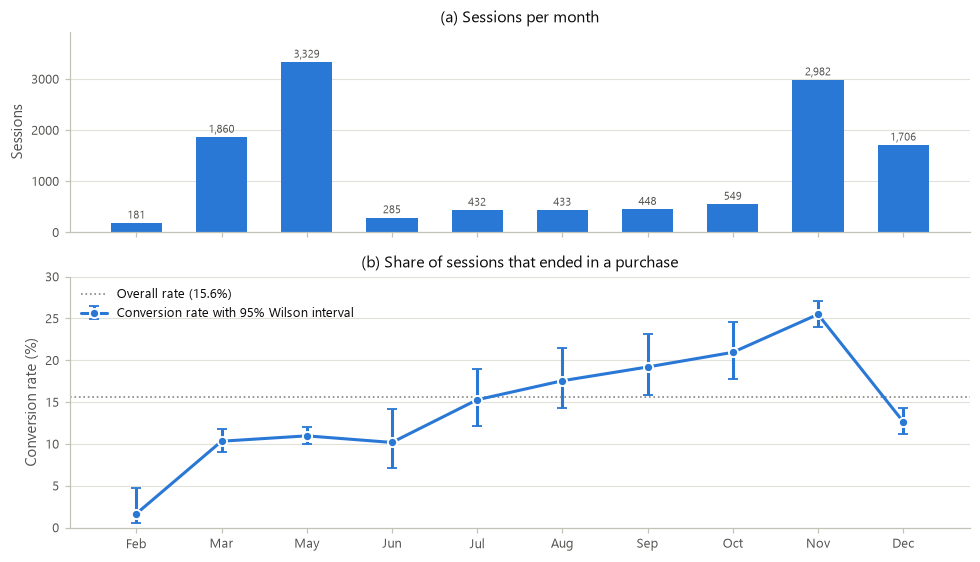

,sum,count,rate,lo,hi
Month,,,,,
Feb,3,181,0.016575,0.005652,0.047591
Mar,192,1860,0.103226,0.090206,0.117881
May,365,3329,0.109643,0.099475,0.120710
June,29,285,0.101754,0.071785,0.142317
Jul,66,432,0.152778,0.121923,0.189754
Aug,76,433,0.175520,0.142586,0.214161
Sep,86,448,0.191964,0.158174,0.230993
Oct,115,549,0.209472,0.177509,0.245472
Nov,760,2982,0.254863,0.239543,0.270812


In [13]:
def wilson(k, n, z=1.96):
    """Wilson score confidence interval for a binomial proportion."""
    p = k / n
    den = 1 + z ** 2 / n
    centre = (p + z ** 2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z ** 2 / (4 * n ** 2)) / den
    return centre - half, centre + half


g = df.groupby("Month")[TARGET].agg(["sum", "count"]).reindex(MONTHS)
g["rate"] = g["sum"] / g["count"]
g["lo"], g["hi"] = zip(*[wilson(k, n) for k, n in zip(g["sum"], g["count"])])
ct_month = pd.crosstab(df["Month"], df[TARGET])
chi2_m, p_m, dof_m, _ = stats.chi2_contingency(ct_month)
k_all, n_all = int(df[TARGET].sum()), len(df)
RESULTS["binomial"] = {
    "p_hat": r(k_all / n_all, 4), "ci": [r(v, 4) for v in wilson(k_all, n_all)],
    "month_rates": {m: r(v, 4) for m, v in g["rate"].items()},
    "month_ci": {m: [r(a, 4), r(b, 4)] for m, a, b in zip(g.index, g["lo"], g["hi"])},
    "month_n": {m: int(v) for m, v in g["count"].items()},
    "chi2_month": r(chi2_m, 1), "dof_month": int(dof_m), "p_month": float(p_m),
}

# Two aligned panels instead of a dual-axis chart: volume on top, conversion rate below
fig, ax = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, gridspec_kw={"height_ratios": [1, 1.25]})
xm = np.arange(len(MONTHS))
ax[0].bar(xm, g["count"], color=BLUE, width=0.6)
for xv, v in zip(xm, g["count"]):
    ax[0].text(xv, v + 40, f"{v:,}", ha="center", va="bottom", fontsize=7.5, color=INK2)
ax[0].set_ylabel("Sessions")
ax[0].set_ylim(0, g["count"].max() * 1.18)
ax[0].set_title("(a) Sessions per month")
ax[1].errorbar(xm, 100 * g["rate"], yerr=[100 * (g["rate"] - g["lo"]), 100 * (g["hi"] - g["rate"])],
               color=BLUE, ecolor=BLUE, marker="o", ms=6, mec="white", mew=1.2, lw=2, capsize=3,
               label="Conversion rate with 95% Wilson interval")
ax[1].axhline(100 * k_all / n_all, color=MUTED, ls=":", lw=1.1, label=f"Overall rate ({100 * k_all / n_all:.1f}%)")
ax[1].set_ylabel("Conversion rate (%)")
ax[1].set_ylim(0, 30)
ax[1].set_xticks(xm, [m[:3] for m in MONTHS])
ax[1].set_title("(b) Share of sessions that ended in a purchase")
ax[1].legend(loc="upper left", fontsize=8.3)
fig.tight_layout()
save(fig, "f08_monthly_conversion")
g

## 5. Mine (III): bivariate and multivariate analysis

In [14]:
# Mann-Whitney U tests: does each numerical feature differ between buyers and non-buyers?
mw_rows = []
buyer = df[TARGET].to_numpy()
for c in NUM:
    a, b = df.loc[buyer, c], df.loc[~buyer, c]
    u, p = stats.mannwhitneyu(a, b, alternative="two-sided")
    auc = u / (len(a) * len(b))
    mw_rows.append({"Feature": c, "Median (buyers)": r(a.median(), 3), "Median (non-buyers)": r(b.median(), 3),
                    "U statistic": float(u), "p-value": float(p), "AUC effect size": r(auc, 3),
                    "Rank-biserial r": r(2 * auc - 1, 3)})
mw = pd.DataFrame(mw_rows)
mw["p (BH-adjusted)"] = stats.false_discovery_control(mw["p-value"])
mw = mw.sort_values("AUC effect size", key=lambda s: (s - 0.5).abs(), ascending=False).reset_index(drop=True)
mw.to_csv(RES_DIR / "mann_whitney.csv", index=False)
RESULTS["mann_whitney"] = mw.to_dict(orient="records")
mw

,Feature,Median (buyers),Median (non-buyers),U statistic,p-value,AUC effect size,Rank-biserial r,p (BH-adjusted)
0,PageValues,16.758,0.000,16951382.0,0.000000e+00,0.863,0.726,0.000000e+00
1,ExitRates,0.016,0.028,5903681.5,3.029894e-169,0.300,-0.399,1.514947e-168
2,ProductRelated_Duration,1109.906,526.000,13145025.5,4.183328e-122,0.669,0.338,1.394443e-121
3,ProductRelated,29.000,16.000,12856227.0,3.693608e-102,0.654,0.309,9.234020e-102
4,Administrative,2.000,1.000,12257665.5,8.904563e-74,0.624,0.248,1.780913e-73
5,Administrative_Duration,52.367,0.000,12193811.0,2.220031e-70,0.621,0.241,3.700051e-70
6,BounceRates,0.000,0.004,7686495.5,1.060090e-56,0.391,-0.218,1.514414e-56
7,Informational,0.000,0.000,11078871.5,4.365438e-35,0.564,0.128,5.456797e-35
8,Informational_Duration,0.000,0.000,11018964.5,4.053185e-34,0.561,0.122,4.503538e-34
9,SpecialDay,0.000,0.000,9098004.5,1.740491e-22,0.463,-0.074,1.740491e-22


In [15]:
# Chi-square tests of independence and Cramer's V for the categorical predictors
chi_rows = []
for c in ["Month", "VisitorType", "Weekend", "TrafficType", "OperatingSystems", "Browser", "Region", "SpecialDay"]:
    col = df[c].astype(str)
    freq = col.value_counts(normalize=True)
    col = col.where(~col.isin(freq[freq < 0.01].index), "Other")   # pool sparse levels
    ct = pd.crosstab(col, df[TARGET])
    chi2_, p_, dof_, exp_ = stats.chi2_contingency(ct)
    v_ = np.sqrt(chi2_ / (ct.values.sum() * (min(ct.shape) - 1)))
    chi_rows.append({"Variable": c, "Levels": int(ct.shape[0]), "Chi-square": r(chi2_, 2), "df": int(dof_),
                     "p-value": float(p_), "Cramer's V": r(v_, 3), "Min expected count": r(exp_.min(), 1)})
chi = pd.DataFrame(chi_rows).sort_values("Cramer's V", ascending=False).reset_index(drop=True)
chi.to_csv(RES_DIR / "chi_square.csv", index=False)
RESULTS["chi_square"] = chi.to_dict(orient="records")
chi

,Variable,Levels,Chi-square,df,p-value,Cramer's V,Min expected count
0,Month,10,376.28,9,1.566845e-75,0.176,28.3
1,TrafficType,12,342.27,11,1.046073e-66,0.167,25.5
2,VisitorType,3,130.67,2,4.225571e-29,0.103,12.7
3,SpecialDay,6,98.17,5,1.282308e-19,0.090,24.1
4,OperatingSystems,5,73.16,4,4.880259e-15,0.077,16.7
5,Browser,8,11.09,7,1.345967e-01,0.030,21.1
6,Region,9,9.68,8,2.882562e-01,0.028,49.7
7,Weekend,2,9.20,1,2.413810e-03,0.027,446.9


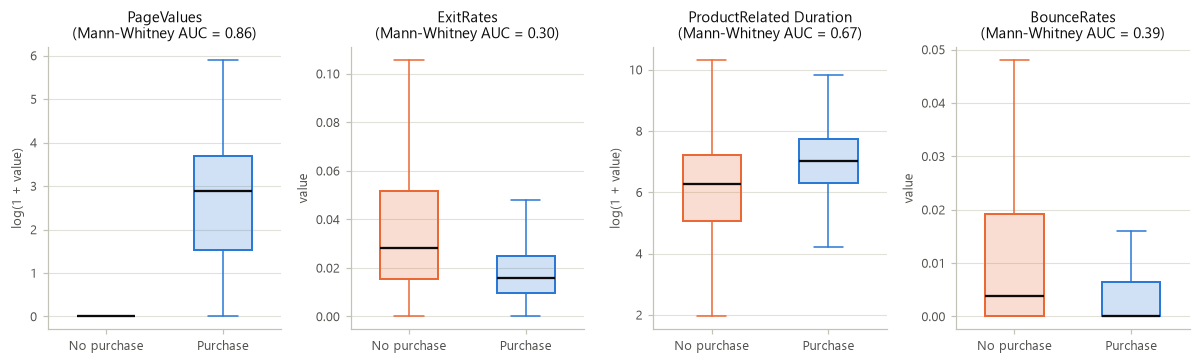

In [16]:
# Figure: key numerical features compared across the two classes ("several batches")
fig, ax = plt.subplots(1, 4, figsize=(11, 3.4))
pairs = [("PageValues", True), ("ExitRates", False), ("ProductRelated_Duration", True), ("BounceRates", False)]
for a, (c, lg) in zip(ax, pairs):
    vals = [np.log1p(df.loc[~buyer, c]) if lg else df.loc[~buyer, c],
            np.log1p(df.loc[buyer, c]) if lg else df.loc[buyer, c]]
    bp = a.boxplot(vals, widths=0.5, patch_artist=True, showfliers=False, medianprops=dict(color=INK, lw=1.5))
    for box, col in zip(bp["boxes"], [NOBUY, BUY]):
        box.set(facecolor=wash(col, 0.22), edgecolor=col, linewidth=1.3)
    for kk, col in enumerate([NOBUY, NOBUY, BUY, BUY]):
        bp["whiskers"][kk].set(color=col); bp["caps"][kk].set(color=col)
    a.set_xticks([1, 2], ["No purchase", "Purchase"], fontsize=8.5)
    auc_c = float(mw.loc[mw.Feature == c, "AUC effect size"].iloc[0])
    a.set_title(f"{c.replace('_', ' ')}\n(Mann-Whitney AUC = {auc_c:.2f})", fontsize=9.5)
    a.set_ylabel("log(1 + value)" if lg else "value", fontsize=8.5)
fig.tight_layout()
save(fig, "f09_features_by_class")

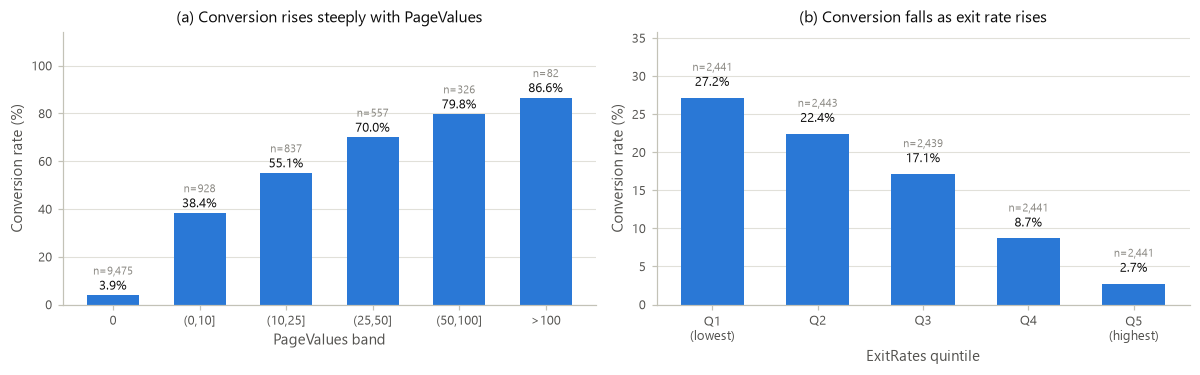

In [17]:
# Figure: conversion rate across PageValues bands and ExitRates quintiles
pv_bins = [-0.01, 0, 10, 25, 50, 100, np.inf]
pv_lab = ["0", "(0,10]", "(10,25]", "(25,50]", "(50,100]", ">100"]
pv = df.groupby(pd.cut(df["PageValues"], pv_bins, labels=pv_lab), observed=False)[TARGET].agg(["mean", "count"])
er = df.groupby(pd.qcut(df["ExitRates"], 5, labels=["Q1\n(lowest)", "Q2", "Q3", "Q4", "Q5\n(highest)"]), observed=False)[TARGET].agg(["mean", "count"])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for a, tab, xl in [(ax[0], pv, "PageValues band"), (ax[1], er, "ExitRates quintile")]:
    a.bar(range(len(tab)), 100 * tab["mean"], color=BLUE, width=0.6)
    for i, (m_, n_) in enumerate(zip(tab["mean"], tab["count"])):
        a.text(i, 100 * m_ + 1.2, f"{100 * m_:.1f}%", ha="center", va="bottom", fontsize=8.3)
        a.text(i, 100 * m_ + 1.2 + 0.075 * max(100 * tab["mean"]), f"n={n_:,}", ha="center", va="bottom",
               fontsize=7, color=MUTED)
    a.set_xticks(range(len(tab)), tab.index.astype(str), fontsize=8.5)
    a.set_xlabel(xl); a.set_ylabel("Conversion rate (%)")
    a.set_ylim(0, max(100 * tab["mean"]) * 1.32)
ax[0].set_title("(a) Conversion rises steeply with PageValues")
ax[1].set_title("(b) Conversion falls as exit rate rises")
fig.tight_layout()
save(fig, "f10_conversion_bands")
RESULTS["pagevalue_bands"] = {k: {"rate": r(v, 4), "n": int(n)} for k, v, n in zip(pv.index.astype(str), pv["mean"], pv["count"])}
RESULTS["exit_quintiles"] = {k.replace("\n", " "): {"rate": r(v, 4), "n": int(n)} for k, v, n in zip(er.index.astype(str), er["mean"], er["count"])}

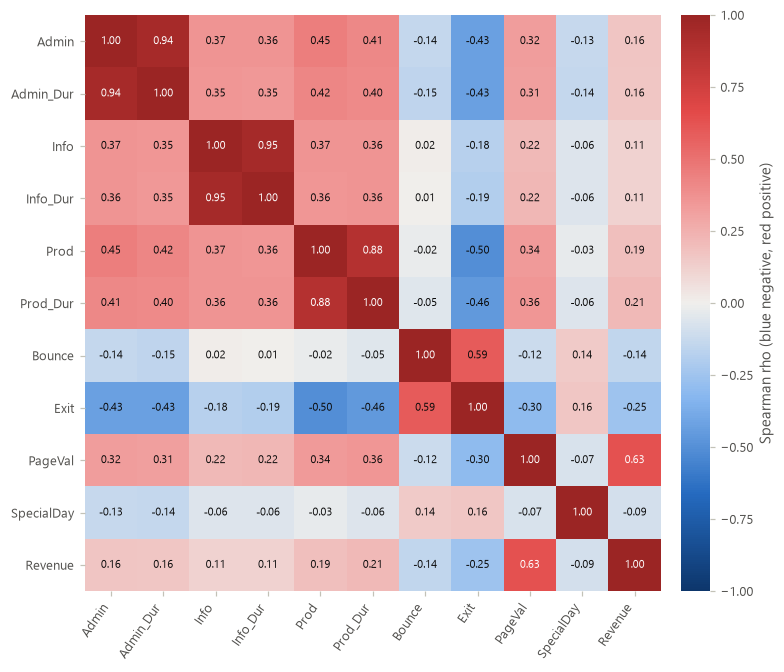

In [18]:
# Figure: Spearman rank-correlation matrix (numerical features and the target), diverging scale
corr = df[NUM + [TARGET]].astype(float).corr(method="spearman")
abbr = ["Admin", "Admin_Dur", "Info", "Info_Dur", "Prod", "Prod_Dur", "Bounce", "Exit", "PageVal", "SpecialDay", "Revenue"]
fig, ax = plt.subplots(figsize=(7.2, 6.2))
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
for i in range(len(corr)):
    for j in range(len(corr)):
        val = corr.values[i, j]
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", fontsize=7.2,
                color="white" if abs(val) > 0.6 else INK)
ax.set_xticks(range(len(abbr)), abbr, rotation=55, ha="right", fontsize=8.5)
ax.set_yticks(range(len(abbr)), abbr, fontsize=8.5)
ax.grid(False)
for sp in ax.spines.values():
    sp.set_visible(False)
cb = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.03)
cb.set_label("Spearman rho (blue negative, red positive)")
cb.outline.set_visible(False)
fig.tight_layout()
save(fig, "f11_spearman_heatmap")
RESULTS["spearman_top"] = {f"{a}~{b}": r(corr.loc[a, b], 3) for a, b in [
    ("BounceRates", "ExitRates"), ("ProductRelated", "ProductRelated_Duration"),
    ("Administrative", "Administrative_Duration"), ("Informational", "Informational_Duration"),
    ("PageValues", TARGET), ("ExitRates", TARGET), ("ProductRelated", TARGET), ("BounceRates", TARGET)]}

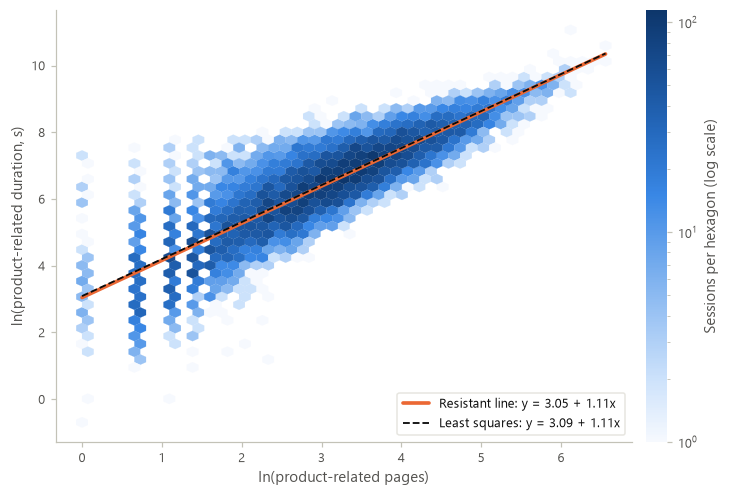

In [19]:
def resistant_line(x, y, iters=20):
    """Tukey's three-group resistant line with iterative polishing of the slope."""
    t1, t2 = np.quantile(x, [1 / 3, 2 / 3])
    L, R = x <= t1, x >= t2
    M = ~L & ~R
    xL, xR = np.median(x[L]), np.median(x[R])
    b = (np.median(y[R]) - np.median(y[L])) / (xR - xL)
    for _ in range(iters):
        res = y - b * x
        db = (np.median(res[R]) - np.median(res[L])) / (xR - xL)
        b += db
        if abs(db) < 1e-7:
            break
    res = y - b * x
    a = (np.median(res[L]) + np.median(res[M]) + np.median(res[R])) / 3
    return a, b


sub = df[(df["ProductRelated"] > 0) & (df["ProductRelated_Duration"] > 0)]
xx, yy = np.log(sub["ProductRelated"].to_numpy(float)), np.log(sub["ProductRelated_Duration"].to_numpy(float))
a_rl, b_rl = resistant_line(xx, yy)
b_ols, a_ols = np.polyfit(xx, yy, 1)
rho_xy = stats.spearmanr(xx, yy).statistic
fig, ax = plt.subplots(figsize=(7, 4.6))
hb = ax.hexbin(xx, yy, gridsize=45, cmap=SEQ, bins="log", mincnt=1, linewidths=0.1)
gx = np.linspace(xx.min(), xx.max(), 50)
ax.plot(gx, a_rl + b_rl * gx, color=ORANGE, lw=2.4, label=f"Resistant line: y = {a_rl:.2f} + {b_rl:.2f}x")
ax.plot(gx, a_ols + b_ols * gx, color=INK, lw=1.2, ls="--", label=f"Least squares: y = {a_ols:.2f} + {b_ols:.2f}x")
ax.set_xlabel("ln(product-related pages)")
ax.set_ylabel("ln(product-related duration, s)")
ax.legend(loc="lower right", fontsize=8.5, frameon=True, facecolor="white", edgecolor=GRID)
cb = fig.colorbar(hb, ax=ax, pad=0.02)
cb.set_label("Sessions per hexagon (log scale)")
cb.outline.set_visible(False)
ax.grid(False)
fig.tight_layout()
save(fig, "f12_resistant_line")
RESULTS["resistant_line"] = {"a": r(a_rl, 3), "b": r(b_rl, 3), "ols_a": r(a_ols, 3), "ols_b": r(b_ols, 3),
                             "spearman": r(rho_xy, 3), "n": int(len(sub)),
                             "sec_per_page_at_median": r(np.exp(a_rl + b_rl * np.median(xx)) / np.exp(np.median(xx)), 1)}

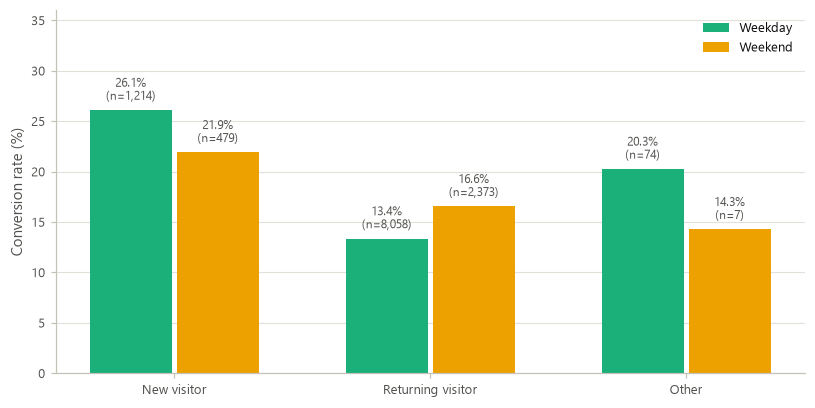

,VisitorType,Weekend,mean,count
0,New_Visitor,False,0.261120,1214
1,New_Visitor,True,0.219207,479
2,Other,False,0.202703,74
3,Other,True,0.142857,7
4,Returning_Visitor,False,0.133656,8058
5,Returning_Visitor,True,0.165613,2373


In [20]:
# Figure: introducing a third variable (visitor type x weekend x purchase)
tw = df.groupby(["VisitorType", "Weekend"])[TARGET].agg(["mean", "count"]).reset_index()
vt_order = ["New_Visitor", "Returning_Visitor", "Other"]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
for k, (wk, col) in enumerate([(False, AQUA), (True, YELLOW)]):
    sub_t = tw[tw["Weekend"] == wk].set_index("VisitorType").reindex(vt_order)
    xs_ = np.arange(len(vt_order)) + (k - 0.5) * 0.34
    ax.bar(xs_, 100 * sub_t["mean"], 0.32, color=col, label="Weekend" if wk else "Weekday")
    for xv, m_, n_ in zip(xs_, sub_t["mean"], sub_t["count"]):
        ax.text(xv, 100 * m_ + 0.7, f"{100 * m_:.1f}%\n(n={n_:,})", ha="center", va="bottom", fontsize=7.6, color=INK2)
ax.set_xticks(range(len(vt_order)), ["New visitor", "Returning visitor", "Other"])
ax.set_ylabel("Conversion rate (%)")
ax.set_ylim(0, 36)
ax.legend(loc="upper right")
fig.tight_layout()
save(fig, "f13_three_way")
vt_rate = df.groupby("VisitorType")[TARGET].mean()
wk_rate = df.groupby("Weekend")[TARGET].mean()
RESULTS["three_way"] = {f"{a}|{'Weekend' if b else 'Weekday'}": {"rate": r(m_, 4), "n": int(n_)}
                        for a, b, m_, n_ in tw[["VisitorType", "Weekend", "mean", "count"]].itertuples(index=False)}
RESULTS["visitor_rate"] = {k: r(v, 4) for k, v in vt_rate.items()}
RESULTS["weekend_rate"] = {("Weekend" if k else "Weekday"): r(v, 4) for k, v in wk_rate.items()}
# Does the new-visitor advantage survive once we control for PageValues > 0?
ctrl = df.assign(PV=np.where(df["PageValues"] > 0, "PageValues>0", "PageValues=0")).groupby(["PV", "VisitorType"])[TARGET].mean()
RESULTS["visitor_rate_by_pv"] = {f"{a}|{b}": r(v, 4) for (a, b), v in ctrl.items()}
tw

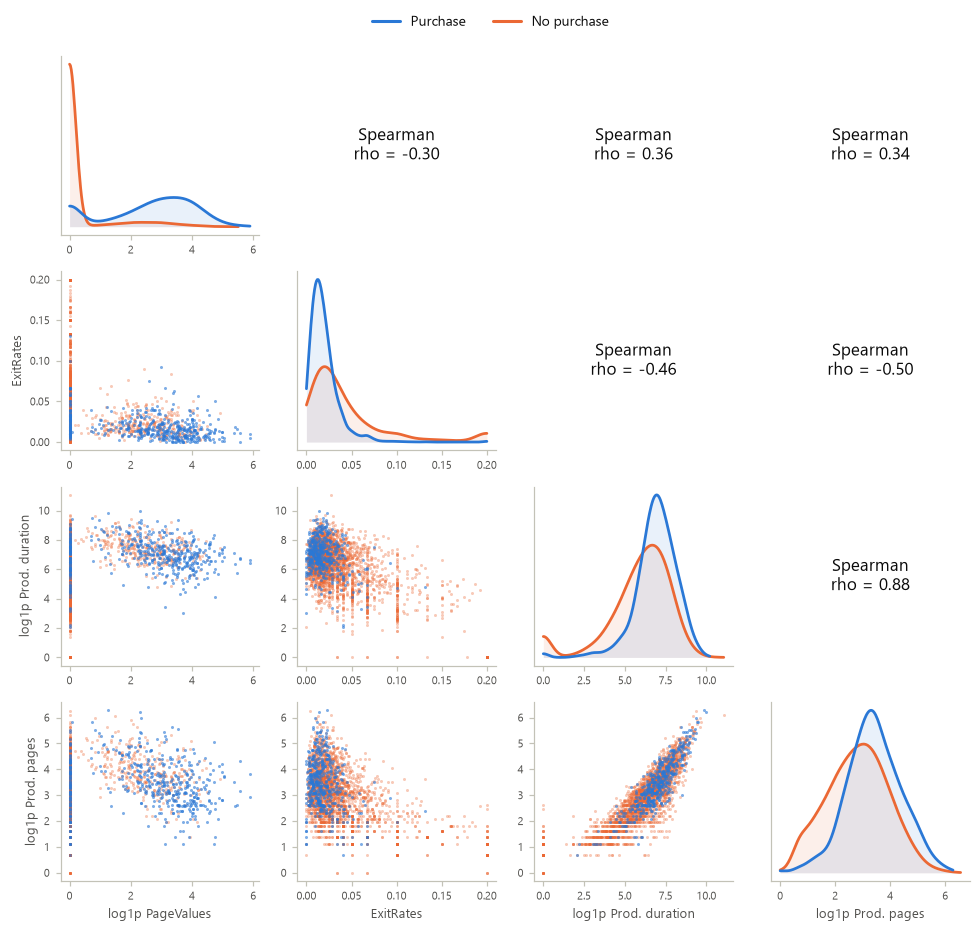

In [21]:
# Figure: pair plot of four key features, coloured by class
pp_cols = {"log1p PageValues": np.log1p(df["PageValues"]), "ExitRates": df["ExitRates"],
           "log1p Prod. duration": np.log1p(df["ProductRelated_Duration"]), "log1p Prod. pages": np.log1p(df["ProductRelated"])}
ppdf = pd.DataFrame(pp_cols)
rng = np.random.default_rng(SEED)
samp = rng.choice(len(ppdf), 3000, replace=False)
names = list(pp_cols)
fig, axes = plt.subplots(4, 4, figsize=(9, 8.4))
for i, yi in enumerate(names):
    for j, xj in enumerate(names):
        a = axes[i, j]
        a.grid(False)
        if i == j:
            for cls, col in [(False, NOBUY), (True, BUY)]:
                v = ppdf.loc[buyer == cls, xj]
                kde = stats.gaussian_kde(v, bw_method=0.25)
                gx = np.linspace(v.min(), v.max(), 200)
                a.plot(gx, kde(gx), color=col, lw=1.8)
                a.fill_between(gx, kde(gx), color=col, alpha=0.10, lw=0)
            a.set_yticks([])
        elif i > j:
            sv = ppdf.iloc[samp]
            bs = buyer[samp]
            a.scatter(sv.loc[~bs, xj], sv.loc[~bs, yi], s=4, color=NOBUY, alpha=0.35, linewidths=0)
            a.scatter(sv.loc[bs, xj], sv.loc[bs, yi], s=4, color=BUY, alpha=0.6, linewidths=0)
        else:
            rho = stats.spearmanr(ppdf[xj], ppdf[yi]).statistic
            a.text(0.5, 0.5, f"Spearman\nrho = {rho:.2f}", ha="center", va="center", fontsize=11, transform=a.transAxes)
            a.axis("off")
        if i == 3:
            a.set_xlabel(xj, fontsize=8.5)
        if j == 0 and i != 0:
            a.set_ylabel(yi, fontsize=8.5)
        a.tick_params(labelsize=7)
handles = [plt.Line2D([], [], color=BUY, lw=2, label="Purchase"),
           plt.Line2D([], [], color=NOBUY, lw=2, label="No purchase")]
fig.legend(handles=handles, loc="upper center", ncol=2, fontsize=9, bbox_to_anchor=(0.5, 1.01))
fig.tight_layout(rect=(0, 0, 1, 0.97))
save(fig, "f14_pairplot")

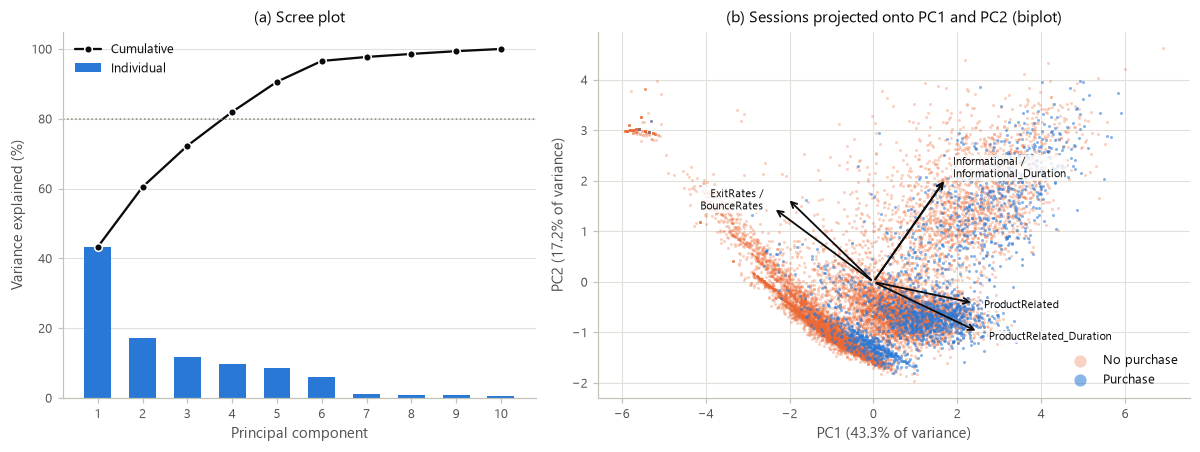

In [22]:
# Figure: principal component analysis of the log-transformed numerical block
Z = StandardScaler().fit_transform(np.log1p(df[NUM].astype(float)))
pca = PCA(random_state=SEED).fit(Z)
scores = pca.transform(Z)[:, :2]
evr = pca.explained_variance_ratio_
fig, ax = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax[0].bar(range(1, len(evr) + 1), 100 * evr, color=BLUE, width=0.6, label="Individual")
ax[0].plot(range(1, len(evr) + 1), 100 * np.cumsum(evr), color=INK, marker="o", ms=5, mec="white", mew=1, lw=1.5, label="Cumulative")
ax[0].axhline(80, color=MUTED, ls=":", lw=1)
ax[0].set_xlabel("Principal component"); ax[0].set_ylabel("Variance explained (%)")
ax[0].set_xticks(range(1, len(evr) + 1)); ax[0].set_title("(a) Scree plot"); ax[0].legend(fontsize=8.5)
ax[1].scatter(scores[~buyer, 0], scores[~buyer, 1], s=4, color=NOBUY, alpha=0.3, linewidths=0, label="No purchase")
ax[1].scatter(scores[buyer, 0], scores[buyer, 1], s=4, color=BUY, alpha=0.55, linewidths=0, label="Purchase")
load = pca.components_[:2].T * np.sqrt(pca.explained_variance_[:2])
top = list(np.argsort(-np.hypot(load[:, 0], load[:, 1]))[:6])
placed = []                                   # merge labels of arrows that point to the same place
for t in top:
    ax[1].annotate("", xy=(load[t, 0] * 3, load[t, 1] * 3), xytext=(0, 0),
                   arrowprops=dict(arrowstyle="->", color=INK, lw=1.2))
    tip_ = np.array([load[t, 0] * 3.3, load[t, 1] * 3.3])
    near = next((pl for pl in placed if np.hypot(*(pl["xy"] - tip_)) < 0.45), None)
    if near:
        near["names"].append(NUM[t])
    else:
        placed.append({"xy": tip_, "names": [NUM[t]]})
for pl in placed:
    ax[1].text(pl["xy"][0], pl["xy"][1], " /\n".join(pl["names"]), fontsize=7.5,
               ha="left" if pl["xy"][0] >= 0 else "right", va="center",
               bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=0.5))
ax[1].set_xlabel(f"PC1 ({100 * evr[0]:.1f}% of variance)")
ax[1].set_ylabel(f"PC2 ({100 * evr[1]:.1f}% of variance)")
ax[1].set_title("(b) Sessions projected onto PC1 and PC2 (biplot)")
ax[1].grid(axis="x")
ax[1].legend(markerscale=4, fontsize=8.5, loc="lower right")
fig.tight_layout()
save(fig, "f15_pca")
RESULTS["pca"] = {"evr": [r(v, 4) for v in evr], "cum2": r(evr[:2].sum(), 4),
                  "n_for_80": int(np.searchsorted(np.cumsum(evr), 0.80) + 1),
                  "pc1_top": [NUM[i] for i in np.argsort(-np.abs(pca.components_[0]))[:4]],
                  "pc2_top": [NUM[i] for i in np.argsort(-np.abs(pca.components_[1]))[:4]]}

## 6. Interact: self-contained HTML dashboard
The dashboard embeds the cleaned data and recomputes histograms and conversion rates in the browser
whenever the user changes the feature, scale, visitor type, day type or month filter. Open `dashboard/index.html`.

In [23]:
dash_data = {
    "num": NUM,
    "cols": {c: [round(float(v), 4) for v in df[c]] for c in NUM},
    "month": df["Month"].str.slice(0, 3).tolist(),
    "visitor": df["VisitorType"].str.replace("_Visitor", "").tolist(),
    "weekend": df["Weekend"].astype(int).tolist(),
    "y": df[TARGET].astype(int).tolist(),
    "months": [m[:3] for m in MONTHS],
}
DASH_TEMPLATE = (ROOT / "src" / "dashboard_template.html").read_text(encoding="utf-8")
(DASH_DIR / "index.html").write_text(DASH_TEMPLATE.replace("/*__DATA__*/null", json.dumps(dash_data, separators=(",", ":"))),
                                     encoding="utf-8")
print("Dashboard written to", DASH_DIR / "index.html")

Dashboard written to C:\Users\nakul\AppData\Roaming\Claude\scratch-workspaces\635db47b-82a4-4829-a53f-a8bb9dba6efa\bf12d992-1e38-4815-99e9-735d88a9c900\scratch-2026-10-12-3f46f7\Nakul_24AD068\dashboard\index.html


## 7. Transform: feature engineering, encoding, scaling and train / validation / test split

In [24]:
mdl = df.copy()
mdl["Month"] = mdl["Month"].replace({"June": "Jun"})
mdl["TotalPages"] = mdl[["Administrative", "Informational", "ProductRelated"]].sum(axis=1)
mdl["TotalDuration"] = mdl[["Administrative_Duration", "Informational_Duration", "ProductRelated_Duration"]].sum(axis=1)
mdl["DurationPerProductPage"] = mdl["ProductRelated_Duration"] / mdl["ProductRelated"].clip(lower=1)
mdl["HasPageValue"] = (mdl["PageValues"] > 0).astype(int)
mdl["Weekend"] = mdl["Weekend"].astype(int)
LOG_COLS = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "PageValues", "TotalPages", "TotalDuration",
            "DurationPerProductPage"]
for c in LOG_COLS:
    mdl[c] = np.log1p(mdl[c])                       # compress heavy right tails
y_all = mdl.pop(TARGET).astype(int).to_numpy()

# Stratified 70 / 15 / 15 split so that every subset keeps the 15.6% purchase rate
idx = np.arange(len(mdl))
idx_tr, idx_tmp = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=SEED)
idx_va, idx_te = train_test_split(idx_tmp, test_size=0.50, stratify=y_all[idx_tmp], random_state=SEED)

CAT_M = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
for c in CAT_M:                                      # pool levels rarer than 1% (learned on train only)
    s = mdl[c].astype(str)
    keep = set(s.iloc[idx_tr].value_counts(normalize=True).loc[lambda v: v >= 0.01].index)
    mdl[c] = s.where(s.isin(keep), "Other")
NUM_M = LOG_COLS + ["BounceRates", "ExitRates", "SpecialDay", "Weekend", "HasPageValue"]
pre = ColumnTransformer([("num", StandardScaler(), NUM_M),
                         ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_M)])
X_tr = pre.fit_transform(mdl.iloc[idx_tr]).astype("float32")
X_va = pre.transform(mdl.iloc[idx_va]).astype("float32")
X_te = pre.transform(mdl.iloc[idx_te]).astype("float32")
y_tr, y_va, y_te = y_all[idx_tr], y_all[idx_va], y_all[idx_te]
feat_names = list(pre.get_feature_names_out())
groups = {}
for k, f in enumerate(feat_names):
    base = f.split("__", 1)[1]
    orig = next((c for c in CAT_M if base.startswith(c + "_")), base) if f.startswith("cat__") else base
    if orig == "HasPageValue":
        orig = "PageValues"                         # the flag is derived from PageValues: one information source
    groups.setdefault(orig, []).append(k)

split_table = pd.DataFrame({
    "Subset": ["Train", "Validation", "Test"],
    "Sessions": [len(y_tr), len(y_va), len(y_te)],
    "Purchases": [int(y_tr.sum()), int(y_va.sum()), int(y_te.sum())],
    "Purchase rate (%)": [r(100 * y_tr.mean(), 2), r(100 * y_va.mean(), 2), r(100 * y_te.mean(), 2)],
})
RESULTS["split"] = split_table.to_dict(orient="records")
RESULTS["n_features_model"] = int(X_tr.shape[1])
RESULTS["n_numeric_model"] = len(NUM_M)
RESULTS["n_onehot_model"] = int(X_tr.shape[1] - len(NUM_M))
neg, posn = np.bincount(y_tr)
class_weight = {0: len(y_tr) / (2 * neg), 1: len(y_tr) / (2 * posn)}
RESULTS["class_weight"] = {str(k): r(v, 4) for k, v in class_weight.items()}
print(split_table, "\nInput dimension:", X_tr.shape[1], "\nClass weights:", class_weight)

       Subset  Sessions  Purchases  Purchase rate (%)
0       Train      8543       1336              15.64
1  Validation      1831        286              15.62
2        Test      1831        286              15.62 
Input dimension: 62 
Class weights: {0: np.float64(0.5926876647703622), 1: np.float64(3.1972305389221556)}


## 8. Mine (IV): deep learning model (Keras multilayer perceptron) with basic hyper-parameter tuning

In [25]:
import tensorflow as tf
import keras
from keras import layers, regularizers

keras.utils.set_random_seed(SEED)
tf.config.experimental.enable_op_determinism()


def build_mlp(input_dim, hidden=(64, 32), dropout=0.3, lr=1e-3, l2=1e-4):
    """Fully connected network: [Dense -> ReLU -> Dropout] x len(hidden) -> Dense(1, sigmoid)."""
    inp = keras.Input(shape=(input_dim,), name="session_features")
    x = inp
    for i, units in enumerate(hidden):
        x = layers.Dense(units, activation="relu", kernel_regularizer=regularizers.l2(l2), name=f"dense_{i + 1}")(x)
        x = layers.Dropout(dropout, name=f"dropout_{i + 1}")(x)
    out = layers.Dense(1, activation="sigmoid", name="purchase_probability")(x)
    model = keras.Model(inp, out, name="purchase_mlp")
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss="binary_crossentropy",
                  metrics=[keras.metrics.BinaryAccuracy(name="accuracy"), keras.metrics.AUC(name="auc"),
                           keras.metrics.AUC(curve="PR", name="pr_auc")])
    return model


def callbacks():
    return [keras.callbacks.EarlyStopping(monitor="val_auc", mode="max", patience=15, restore_best_weights=True),
            keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=6, min_lr=1e-5)]


grid = [dict(hidden=h, dropout=d, lr=lr) for h in [(32,), (64, 32), (128, 64, 32)]
        for d in [0.2, 0.4] for lr in [1e-3, 3e-4]]
if FAST:
    grid = grid[2:4]
EPOCHS = 30 if FAST else 150

tuning, best = [], None
t0 = time.time()
for i, cfg in enumerate(grid):
    keras.utils.set_random_seed(SEED)
    model = build_mlp(X_tr.shape[1], **cfg)
    hist = model.fit(X_tr, y_tr, validation_data=(X_va, y_va), epochs=EPOCHS, batch_size=128,
                     class_weight=class_weight, callbacks=callbacks(), verbose=0)
    pv_ = model.predict(X_va, verbose=0).ravel()
    row = {"Config": i + 1, "Hidden layers": "-".join(map(str, cfg["hidden"])), "Dropout": cfg["dropout"],
           "Learning rate": cfg["lr"], "Epochs run": len(hist.history["loss"]),
           "Best epoch": int(np.argmax(hist.history["val_auc"]) + 1),
           "Val ROC-AUC": r(roc_auc_score(y_va, pv_), 4), "Val PR-AUC": r(average_precision_score(y_va, pv_), 4),
           "Params": int(model.count_params())}
    tuning.append(row)
    print(row)
    if best is None or row["Val ROC-AUC"] > best["row"]["Val ROC-AUC"]:
        best = {"row": row, "cfg": cfg, "model": model, "history": hist.history}
tuning = pd.DataFrame(tuning)
tuning.to_csv(RES_DIR / "hyperparameter_tuning.csv", index=False)
RESULTS["tuning"] = tuning.to_dict(orient="records")
RESULTS["tuning_seconds"] = r(time.time() - t0, 1)
RESULTS["best_config"] = best["row"]
model = best["model"]
model.save(RES_DIR / "best_mlp.keras")
model.summary()

{'Config': 1, 'Hidden layers': '32', 'Dropout': 0.2, 'Learning rate': 0.001, 'Epochs run': 46, 'Best epoch': 31, 'Val ROC-AUC': 0.9342, 'Val PR-AUC': 0.7415, 'Params': 2049}


{'Config': 2, 'Hidden layers': '32', 'Dropout': 0.2, 'Learning rate': 0.0003, 'Epochs run': 116, 'Best epoch': 101, 'Val ROC-AUC': 0.9331, 'Val PR-AUC': 0.7395, 'Params': 2049}


{'Config': 3, 'Hidden layers': '32', 'Dropout': 0.4, 'Learning rate': 0.001, 'Epochs run': 60, 'Best epoch': 45, 'Val ROC-AUC': 0.9338, 'Val PR-AUC': 0.7389, 'Params': 2049}


{'Config': 4, 'Hidden layers': '32', 'Dropout': 0.4, 'Learning rate': 0.0003, 'Epochs run': 113, 'Best epoch': 98, 'Val ROC-AUC': 0.9335, 'Val PR-AUC': 0.7405, 'Params': 2049}


{'Config': 5, 'Hidden layers': '64-32', 'Dropout': 0.2, 'Learning rate': 0.001, 'Epochs run': 32, 'Best epoch': 17, 'Val ROC-AUC': 0.9318, 'Val PR-AUC': 0.7321, 'Params': 6145}


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ session_features (InputLayer)   │ (None, 62)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,016 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ purchase_probability (Dense)    │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,149 (24.02 KB)

 Trainable params: 2,049 (8.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 4,100 (16.02 KB)

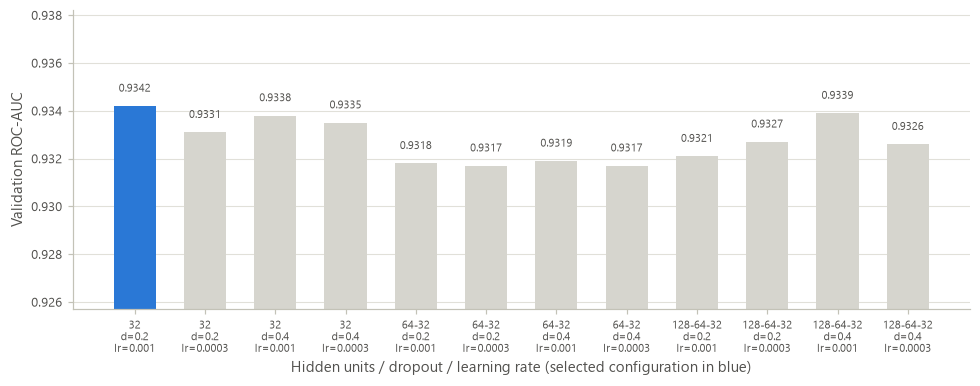

In [26]:
# Figure: hyper-parameter search results (validation ROC-AUC for every configuration)
fig, ax = plt.subplots(figsize=(9, 3.6))
lab = [f"{t['Hidden layers']}\nd={t['Dropout']}\nlr={t['Learning rate']:g}" for t in tuning.to_dict("records")]
cols = [BLUE if t["Config"] == best["row"]["Config"] else NEUTRAL for t in tuning.to_dict("records")]
ax.bar(range(len(tuning)), tuning["Val ROC-AUC"], color=cols, width=0.6)
for i, v in enumerate(tuning["Val ROC-AUC"]):
    ax.text(i, v + 0.0005, f"{v:.4f}", ha="center", va="bottom", fontsize=7.2, color=INK2)
lo_ = tuning["Val ROC-AUC"].min()
ax.set_ylim(lo_ - 0.006, tuning["Val ROC-AUC"].max() + 0.004)
ax.set_xticks(range(len(tuning)), lab, fontsize=7)
ax.set_ylabel("Validation ROC-AUC")
ax.set_xlabel("Hidden units / dropout / learning rate (selected configuration in blue)")
fig.tight_layout()
save(fig, "f17_tuning")

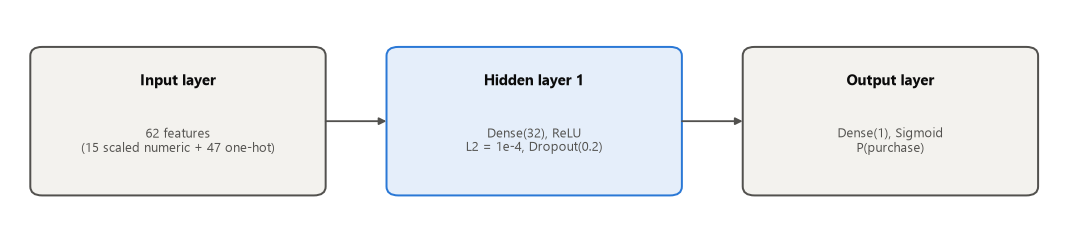

In [27]:
# Figure: architecture of the selected network
cfg = best["cfg"]
blocks = [("Input layer", f"{X_tr.shape[1]} features\n(15 scaled numeric + {X_tr.shape[1] - 15} one-hot)")]
for i, u in enumerate(cfg["hidden"]):
    blocks.append((f"Hidden layer {i + 1}", f"Dense({u}), ReLU\nL2 = 1e-4, Dropout({cfg['dropout']})"))
blocks.append(("Output layer", "Dense(1), Sigmoid\nP(purchase)"))
fig, ax = plt.subplots(figsize=(10, 2.3))
ax.set_xlim(0, len(blocks) * 2.4); ax.set_ylim(0, 2); ax.axis("off")
for i, (title, body) in enumerate(blocks):
    x0 = i * 2.4 + 0.15
    edge = BLUE if 0 < i < len(blocks) - 1 else INK2
    face = wash(BLUE, 0.12) if 0 < i < len(blocks) - 1 else "#f3f2ee"
    ax.add_patch(FancyBboxPatch((x0, 0.35), 1.95, 1.3, boxstyle="round,pad=0.02,rounding_size=0.08",
                                facecolor=face, edgecolor=edge, linewidth=1.3))
    ax.text(x0 + 0.975, 1.36, title, ha="center", va="center", fontsize=9.5, fontweight="bold")
    ax.text(x0 + 0.975, 0.82, body, ha="center", va="center", fontsize=8.2, color=INK2)
    if i < len(blocks) - 1:
        ax.annotate("", xy=(x0 + 2.4, 1.0), xytext=(x0 + 1.95, 1.0), arrowprops=dict(arrowstyle="-|>", color=INK2, lw=1.2))
fig.tight_layout()
save(fig, "f19_architecture")

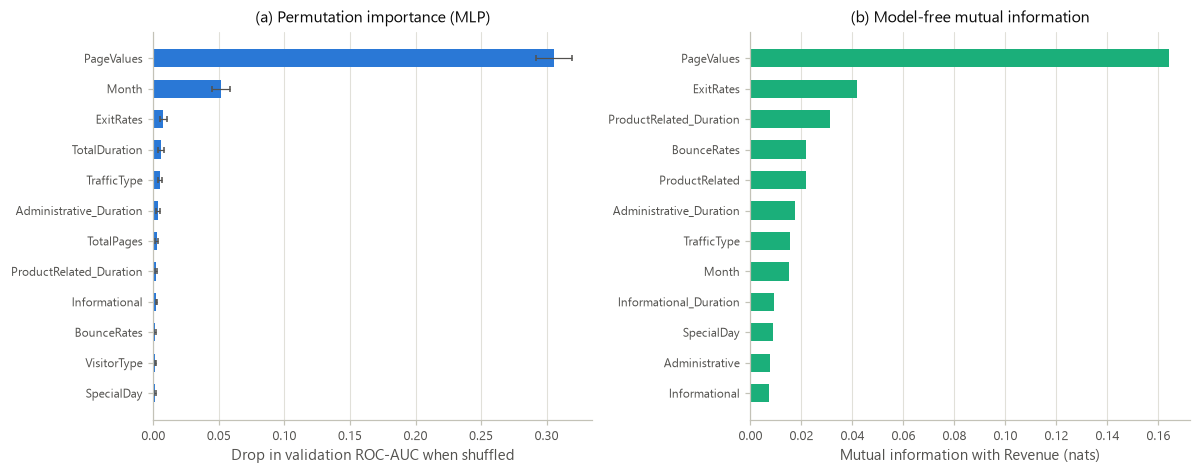

,Feature,Mean AUC drop,SD
0,PageValues,0.305584,0.013482
1,Month,0.051694,0.006995
2,ExitRates,0.007530,0.002736
3,TotalDuration,0.005591,0.002184
4,TrafficType,0.005010,0.001657
5,Administrative_Duration,0.003291,0.001505
6,TotalPages,0.002460,0.001273
7,ProductRelated_Duration,0.002381,0.000763
8,Informational,0.002353,0.000552
9,BounceRates,0.001568,0.000721


In [28]:
# Feature analysis: permutation importance (grouped by original field) and mutual information
p_va = model.predict(X_va, verbose=0).ravel()
base_auc = roc_auc_score(y_va, p_va)
rng = np.random.default_rng(SEED)
imp_rows = []
for name, cols_ in groups.items():
    drops = []
    for _ in range(10):
        Xp = X_va.copy()
        perm = rng.permutation(len(Xp))
        Xp[:, cols_] = X_va[perm][:, cols_]          # shuffle the whole group jointly
        drops.append(base_auc - roc_auc_score(y_va, model.predict(Xp, verbose=0).ravel()))
    imp_rows.append({"Feature": name, "Mean AUC drop": float(np.mean(drops)), "SD": float(np.std(drops))})
imp = pd.DataFrame(imp_rows).sort_values("Mean AUC drop", ascending=False).reset_index(drop=True)
imp.to_csv(RES_DIR / "permutation_importance.csv", index=False)

mi_df = df[NUM + CAT].copy()
for c in ["Month", "VisitorType"]:
    mi_df[c] = mi_df[c].astype("category").cat.codes
mi_df["Weekend"] = mi_df["Weekend"].astype(int)
disc = [c in CAT for c in mi_df.columns]
mi = mutual_info_classif(mi_df.to_numpy(float), df[TARGET].astype(int), discrete_features=disc, random_state=SEED)
mi = pd.Series(mi, index=mi_df.columns).sort_values(ascending=False)
RESULTS["perm_importance"] = [{k: (r(v, 5) if isinstance(v, float) else v) for k, v in d.items()} for d in imp.to_dict("records")]
RESULTS["mutual_info"] = {k: r(v, 4) for k, v in mi.items()}
RESULTS["val_auc_base"] = r(base_auc, 4)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
top_imp = imp.head(12).iloc[::-1]
ax[0].barh(top_imp["Feature"], top_imp["Mean AUC drop"], xerr=top_imp["SD"], color=BLUE, height=0.6,
           error_kw=dict(ecolor=INK2, lw=0.8, capsize=2))
ax[0].set_xlabel("Drop in validation ROC-AUC when shuffled")
ax[0].set_title("(a) Permutation importance (MLP)")
ax[0].tick_params(axis="y", labelsize=8)
ax[0].grid(axis="x"); ax[0].grid(axis="y", visible=False)
top_mi = mi.head(12).iloc[::-1]
ax[1].barh(top_mi.index, top_mi.values, color=AQUA, height=0.6)
ax[1].set_xlabel("Mutual information with Revenue (nats)")
ax[1].set_title("(b) Model-free mutual information")
ax[1].tick_params(axis="y", labelsize=8)
ax[1].grid(axis="x"); ax[1].grid(axis="y", visible=False)
fig.tight_layout()
save(fig, "f18_feature_importance")
imp.head(10)

## 9. Represent and Refine: evaluation on the untouched test set

In [29]:
hist = best["history"]
p_te = model.predict(X_te, verbose=0).ravel()
prec_v, rec_v, thr_v = precision_recall_curve(y_va, p_va)
f1_v = 2 * prec_v[:-1] * rec_v[:-1] / np.maximum(prec_v[:-1] + rec_v[:-1], 1e-12)
thr_best = float(thr_v[np.argmax(f1_v)])          # threshold chosen on validation data only

logreg = LogisticRegression(class_weight="balanced", max_iter=5000, random_state=SEED).fit(X_tr, y_tr)
p_te_lr = logreg.predict_proba(X_te)[:, 1]
p_va_lr = logreg.predict_proba(X_va)[:, 1]
pl_, rl_, tl_ = precision_recall_curve(y_va, p_va_lr)
f1_l = 2 * pl_[:-1] * rl_[:-1] / np.maximum(pl_[:-1] + rl_[:-1], 1e-12)
thr_lr = float(tl_[np.argmax(f1_l)])


def metrics(y, p, t):
    yhat = (p >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, yhat).ravel()
    return {"threshold": r(t, 3), "accuracy": r(accuracy_score(y, yhat), 4),
            "balanced_accuracy": r(balanced_accuracy_score(y, yhat), 4),
            "precision": r(precision_score(y, yhat), 4), "recall": r(recall_score(y, yhat), 4),
            "specificity": r(tn / (tn + fp), 4), "f1": r(f1_score(y, yhat), 4),
            "mcc": r(matthews_corrcoef(y, yhat), 4), "roc_auc": r(roc_auc_score(y, p), 4),
            "pr_auc": r(average_precision_score(y, p), 4), "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp)}


RESULTS["test_mlp_default"] = metrics(y_te, p_te, 0.5)
RESULTS["test_mlp_tuned"] = metrics(y_te, p_te, thr_best)
RESULTS["test_logreg_tuned"] = metrics(y_te, p_te_lr, thr_lr)
RESULTS["test_logreg_default"] = metrics(y_te, p_te_lr, 0.5)
RESULTS["history_final"] = {k: [r(v, 5) for v in vals] for k, vals in hist.items() if k != "learning_rate"}
RESULTS["best_epoch"] = int(np.argmax(hist["val_auc"]) + 1)
pd.DataFrame({"MLP (t=0.5)": RESULTS["test_mlp_default"], f"MLP (t={thr_best:.2f})": RESULTS["test_mlp_tuned"],
              "LogReg (t=0.5)": RESULTS["test_logreg_default"], f"LogReg (t={thr_lr:.2f})": RESULTS["test_logreg_tuned"]})

,MLP (t=0.5),MLP (t=0.65),LogReg (t=0.5),LogReg (t=0.59)
threshold,0.5000,0.6480,0.5000,0.5910
accuracy,0.8547,0.8869,0.8624,0.8793
balanced_accuracy,0.8555,0.8490,0.8444,0.8473
precision,0.5213,0.6053,0.5392,0.5827
recall,0.8566,0.7937,0.8182,0.8007
specificity,0.8544,0.9042,0.8706,0.8939
f1,0.6481,0.6868,0.6500,0.6745
mcc,0.5909,0.6278,0.5880,0.6142
roc_auc,0.9314,0.9314,0.9184,0.9184
pr_auc,0.7400,0.7400,0.6542,0.6542


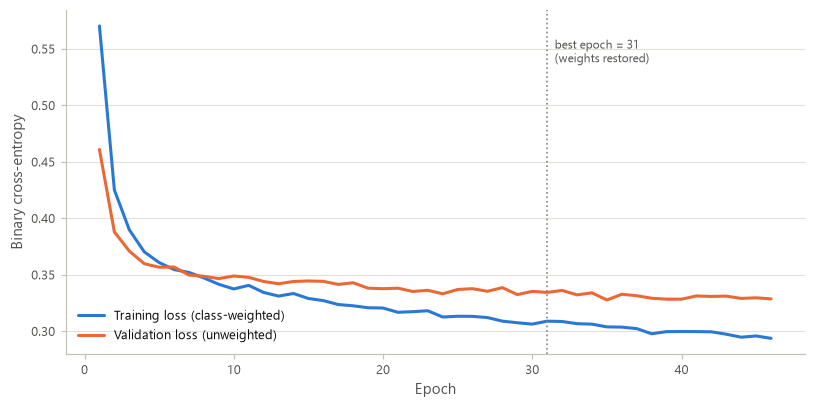

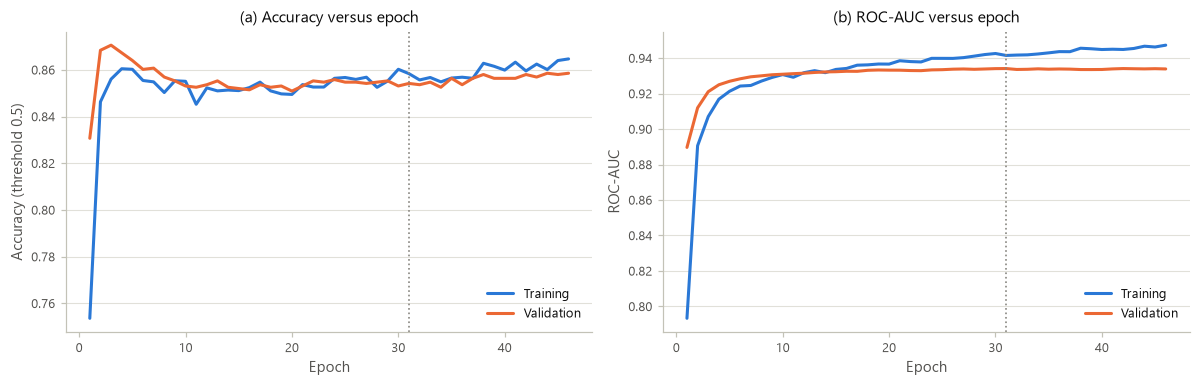

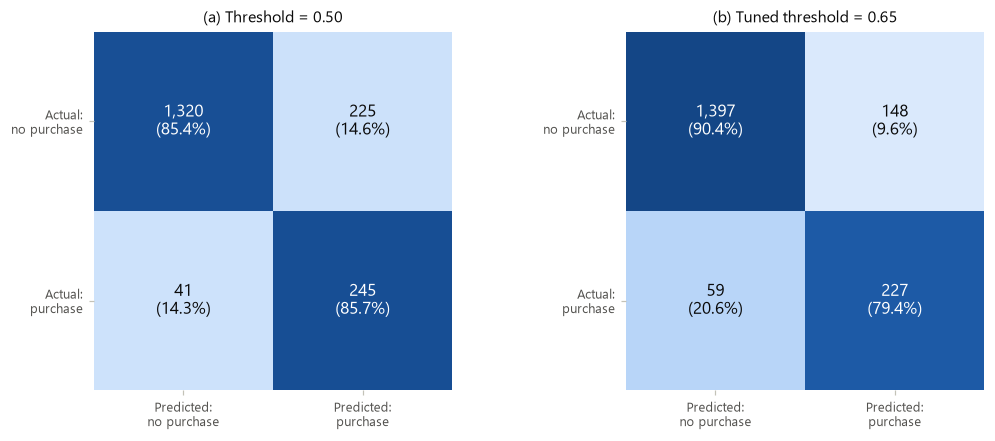

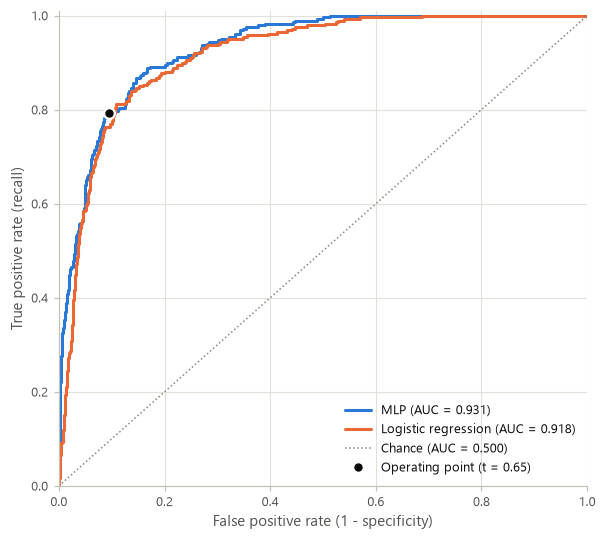

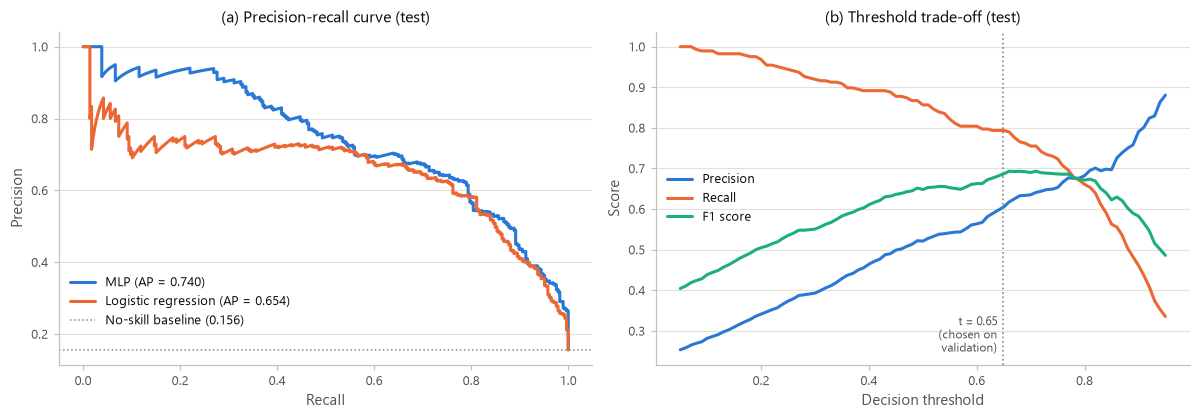

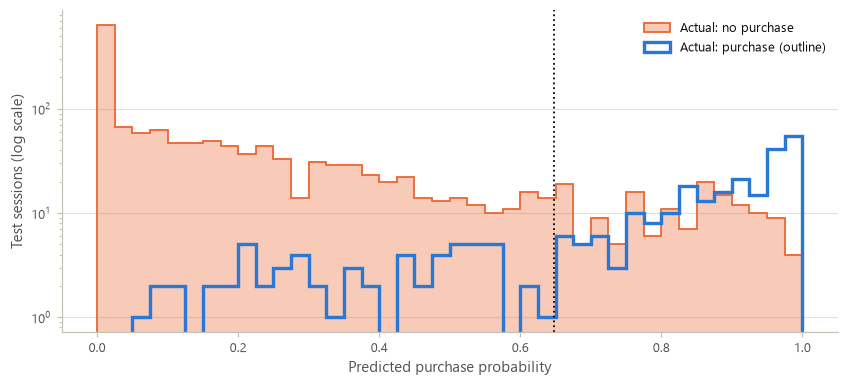

In [30]:
ep = np.arange(1, len(hist["loss"]) + 1)
be = RESULTS["best_epoch"]
fig, ax = plt.subplots(figsize=(7.5, 3.8))
ax.plot(ep, hist["loss"], color=BLUE, lw=2, label="Training loss (class-weighted)")
ax.plot(ep, hist["val_loss"], color=ORANGE, lw=2, label="Validation loss (unweighted)")
ax.axvline(be, color=MUTED, ls=":", lw=1.1)
ax.text(be + 0.5, max(hist["loss"]) * 0.98, f"best epoch = {be}\n(weights restored)", fontsize=8, va="top", color=INK2)
ax.set_xlabel("Epoch"); ax.set_ylabel("Binary cross-entropy")
ax.legend()
fig.tight_layout()
save(fig, "f20_loss_curve")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
ax[0].plot(ep, hist["accuracy"], color=BLUE, lw=2, label="Training")
ax[0].plot(ep, hist["val_accuracy"], color=ORANGE, lw=2, label="Validation")
ax[0].set_title("(a) Accuracy versus epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy (threshold 0.5)")
ax[1].plot(ep, hist["auc"], color=BLUE, lw=2, label="Training")
ax[1].plot(ep, hist["val_auc"], color=ORANGE, lw=2, label="Validation")
ax[1].set_title("(b) ROC-AUC versus epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("ROC-AUC")
for a in ax:
    a.axvline(be, color=MUTED, ls=":", lw=1.1)
    a.legend()
fig.tight_layout()
save(fig, "f21_accuracy_auc_curves")

fig, ax = plt.subplots(1, 2, figsize=(10, 4.1))
for a, (key, ttl) in zip(ax, [("test_mlp_default", "(a) Threshold = 0.50"),
                              ("test_mlp_tuned", f"(b) Tuned threshold = {thr_best:.2f}")]):
    m_ = RESULTS[key]
    cm = np.array([[m_["tn"], m_["fp"]], [m_["fn"], m_["tp"]]])
    rowpct = cm / cm.sum(axis=1, keepdims=True)
    a.imshow(rowpct, cmap=SEQ, vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]:,}\n({100 * rowpct[i, j]:.1f}%)", ha="center", va="center", fontsize=11,
                   color="white" if rowpct[i, j] > 0.55 else INK)
    a.set_xticks([0, 1], ["Predicted:\nno purchase", "Predicted:\npurchase"])
    a.set_yticks([0, 1], ["Actual:\nno purchase", "Actual:\npurchase"])
    a.set_title(ttl); a.grid(False)
    for sp in a.spines.values():
        sp.set_visible(False)
fig.tight_layout()
save(fig, "f22_confusion_matrix")

fig, ax = plt.subplots(figsize=(5.6, 5))
for p_, lab_, col in [(p_te, f"MLP (AUC = {RESULTS['test_mlp_tuned']['roc_auc']:.3f})", BLUE),
                      (p_te_lr, f"Logistic regression (AUC = {RESULTS['test_logreg_tuned']['roc_auc']:.3f})", ORANGE)]:
    fpr, tpr, _ = roc_curve(y_te, p_)
    ax.plot(fpr, tpr, color=col, lw=2, label=lab_)
ax.plot([0, 1], [0, 1], color=MUTED, ls=":", lw=1, label="Chance (AUC = 0.500)")
m_ = RESULTS["test_mlp_tuned"]
ax.plot(1 - m_["specificity"], m_["recall"], "o", color=INK, ms=7, mec="white", mew=1.5, label=f"Operating point (t = {thr_best:.2f})")
ax.set_xlabel("False positive rate (1 - specificity)"); ax.set_ylabel("True positive rate (recall)")
ax.legend(loc="lower right", fontsize=8.3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.01)
ax.grid(axis="x")
fig.tight_layout()
save(fig, "f23_roc_curve")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.9))
pp, rr_, _ = precision_recall_curve(y_te, p_te)
pl2, rl2, _ = precision_recall_curve(y_te, p_te_lr)
ax[0].plot(rr_, pp, color=BLUE, lw=2, label=f"MLP (AP = {RESULTS['test_mlp_tuned']['pr_auc']:.3f})")
ax[0].plot(rl2, pl2, color=ORANGE, lw=2, label=f"Logistic regression (AP = {RESULTS['test_logreg_tuned']['pr_auc']:.3f})")
ax[0].axhline(y_te.mean(), color=MUTED, ls=":", lw=1, label=f"No-skill baseline ({y_te.mean():.3f})")
ax[0].set_xlabel("Recall"); ax[0].set_ylabel("Precision"); ax[0].set_title("(a) Precision-recall curve (test)")
ax[0].legend(fontsize=8.2, loc="lower left", bbox_to_anchor=(0.0, 0.08))
ts = np.linspace(0.05, 0.95, 91)
P = [precision_score(y_te, (p_te >= t).astype(int), zero_division=0) for t in ts]
R = [recall_score(y_te, (p_te >= t).astype(int)) for t in ts]
F = [f1_score(y_te, (p_te >= t).astype(int)) for t in ts]
ax[1].plot(ts, P, color=BLUE, lw=2, label="Precision")
ax[1].plot(ts, R, color=ORANGE, lw=2, label="Recall")
ax[1].plot(ts, F, color=AQUA, lw=2, label="F1 score")
ax[1].axvline(thr_best, color=MUTED, lw=1.1, ls=":")
ax[1].text(thr_best - 0.01, 0.04, f"t = {thr_best:.2f}\n(chosen on\nvalidation)", fontsize=8, ha="right", color=INK2,
           transform=ax[1].get_xaxis_transform())
ax[1].set_xlabel("Decision threshold"); ax[1].set_ylabel("Score"); ax[1].set_title("(b) Threshold trade-off (test)")
ax[1].legend(fontsize=8.2)
fig.tight_layout()
save(fig, "f24_pr_threshold")

fig, ax = plt.subplots(figsize=(7.8, 3.6))
bins_ = np.linspace(0, 1, 41)
ax.hist(p_te[y_te == 0], bins=bins_, histtype="stepfilled", color=wash(NOBUY, 0.35), edgecolor=NOBUY, linewidth=1.2,
        label="Actual: no purchase")
ax.hist(p_te[y_te == 1], bins=bins_, histtype="step", color=BUY, linewidth=2.2,
        label="Actual: purchase (outline)")
ax.axvline(thr_best, color=INK, ls=":", lw=1.2)
ax.set_yscale("log")
ax.set_xlabel("Predicted purchase probability"); ax.set_ylabel("Test sessions (log scale)")
ax.legend()
fig.tight_layout()
save(fig, "f25_score_distribution")
RESULTS["score_medians"] = {"no_purchase": r(np.median(p_te[y_te == 0]), 4), "purchase": r(np.median(p_te[y_te == 1]), 4)}
RESULTS["fn_with_zero_pagevalue_pct"] = r(100 * (mdl.iloc[idx_te]["HasPageValue"].to_numpy()[(y_te == 1) & (p_te < thr_best)] == 0).mean(), 1)

In [31]:
RESULTS["versions"] = {"python": sys.version.split()[0], "numpy": np.__version__, "pandas": pd.__version__,
                       "tensorflow": tf.__version__, "keras": keras.__version__}
RESULTS["audit"] = audit
(RES_DIR / "results.json").write_text(json.dumps(RESULTS, indent=1, default=float), encoding="utf-8")
print("Saved", RES_DIR / "results.json")

Saved C:\Users\nakul\AppData\Roaming\Claude\scratch-workspaces\635db47b-82a4-4829-a53f-a8bb9dba6efa\bf12d992-1e38-4815-99e9-735d88a9c900\scratch-2026-10-12-3f46f7\Nakul_24AD068\results\results.json
